This notebook analyses interesting SI-model snapshots on the Karate network.

In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
import numpy as np
import pandas as pd
import pickle
import networkx as nx
import matplotlib as mpl
from matplotlib import pyplot as plt

import warnings

import propnetscore.node_selection as ns

In [7]:
plt.rcParams.update({
    "font.family": "Calibri",
    "svg.fonttype": "none"   # keeps text editable in Inkscape
})

In [8]:
# Load the network exactly as used in the simulations
with open("karate/network.gpickle", "rb") as f:
    G = pickle.load(f)
    adjacency_matrix = nx.to_numpy_array(G, weight=None)

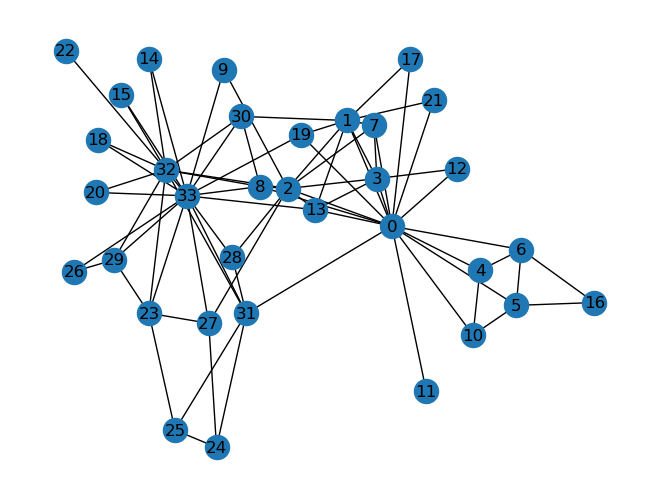

In [9]:
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)

In [10]:
# Load snapshots which appear often enough in simulations that accurate inference of source distribution is possible.

dfs = dict()

dfs[0] = pd.read_csv('karate/interesting_snapshots/source=0_run=38.csv')
dfs[1] = pd.read_csv('karate/interesting_snapshots/source=0_run=46.csv')
dfs[2] = pd.read_csv('karate/interesting_snapshots/source=0_run=71.csv')
dfs[3] = pd.read_csv('karate/interesting_snapshots/source=1_run=33.csv')
dfs[4] = pd.read_csv('karate/interesting_snapshots/source=1_run=70.csv')
dfs[5] = pd.read_csv('karate/interesting_snapshots/source=2_run=41.csv')
dfs[6] = pd.read_csv('karate/interesting_snapshots/source=33_run=15.csv')
dfs[7] = pd.read_csv('karate/interesting_snapshots/source=33_run=68.csv')
dfs[8] = pd.read_csv('karate/interesting_snapshots/source=33_run=81.csv')
dfs[9] = pd.read_csv('karate/interesting_snapshots/source=33_run=87.csv')

for i in range(10):
    dfs[i]["uniform"] = dfs[i]["infected"]
    dfs[i]["uniform"] = dfs[i]["uniform"]/dfs[i]["uniform"].sum()

In [11]:
# Each snapshot is a dataframe 
# Each row is a node (snapshot encoded as 0/1 in column "infected")
# Each node has the following information:
# - How often did this snapshot arise from THIS node being the source (note: in total there were an equal number of simulations from each node)
# - True probability of this node being the source (inferred from the above by empirical frequency)
# - For each of several models, what is the predicted probability of this node being the source

dfs[2]

,node,infected,counts,true_prob,monte_carlo_n=10,soft_margin_a=0.4_n=10,soft_margin_a=0.3_n=10,soft_margin_a=0.2_n=10,soft_margin_a=0.15_n=10,soft_margin_a=0.1_n=10,...,soft_margin_a=0.1_n=1000,static_gnn_n=1000,monte_carlo_n=10000,soft_margin_a=0.4_n=10000,soft_margin_a=0.3_n=10000,soft_margin_a=0.2_n=10000,soft_margin_a=0.15_n=10000,soft_margin_a=0.1_n=10000,static_gnn_n=10000,uniform
0,0,1,23,0.056511,4.566097e-04,0.140412,0.155106,0.144805,9.789608e-02,1.470430e-02,...,2.579314e-03,0.058189,4.154277e-04,0.119110,0.117680,0.097812,0.079238,0.050133,0.084038,0.090909
1,1,1,6,0.014742,3.164900e-06,0.052248,0.023491,0.001614,3.285294e-05,2.306373e-10,...,8.220911e-02,0.028305,3.510147e-04,0.086958,0.074094,0.049395,0.032014,0.013135,0.032121,0.090909
2,2,0,0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,3,1,23,0.056511,2.253602e-04,0.070693,0.038677,0.003557,1.022517e-04,2.641961e-09,...,1.805355e-03,0.042379,3.243499e-03,0.089384,0.080254,0.065624,0.056494,0.029784,0.046241,0.090909
4,4,1,93,0.228501,8.112450e-02,0.119862,0.125242,0.079479,2.452375e-02,2.969135e-04,...,9.007029e-02,0.197756,2.961486e-01,0.108640,0.124473,0.154327,0.165715,0.110100,0.191418,0.090909
5,5,1,47,0.115479,8.142867e-03,0.053841,0.027215,0.001963,3.538852e-05,2.311805e-10,...,2.184765e-02,0.125002,1.726525e-01,0.105580,0.116297,0.124294,0.113263,0.098396,0.126015,0.090909
6,6,1,57,0.140049,6.910509e-02,0.129534,0.181694,0.352410,5.942404e-01,9.248077e-01,...,5.602453e-01,0.125002,1.588278e-01,0.104147,0.114950,0.131921,0.146165,0.173120,0.126015,0.090909
7,7,1,18,0.044226,3.576408e-03,0.052292,0.024857,0.001747,3.613031e-05,2.863432e-10,...,1.475363e-02,0.065053,8.864569e-03,0.087539,0.081010,0.070188,0.071478,0.116043,0.064676,0.090909
8,8,0,0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,9,0,0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [12]:
# The models include
# - Mean-Field Monte Carlo estimator for different n [number of simulations per node used to compute the Monte Carlo estimate]
# - Soft margin estimator (SME) for different parameters a [soft margin parameter] and n [number of simulations per node used to compute the Monte Carlo estimate]
# - Static GNN for different training set sizes n [number of simulations per node used to compute the Monte Carlo estimate]

dfs[0].columns

Index(['node', 'infected', 'counts', 'true_prob', 'monte_carlo_n=10',
       'soft_margin_a=0.4_n=10', 'soft_margin_a=0.3_n=10',
       'soft_margin_a=0.2_n=10', 'soft_margin_a=0.15_n=10',
       'soft_margin_a=0.1_n=10', 'static_gnn_n=10', 'monte_carlo_n=100',
       'soft_margin_a=0.4_n=100', 'soft_margin_a=0.3_n=100',
       'soft_margin_a=0.2_n=100', 'soft_margin_a=0.15_n=100',
       'soft_margin_a=0.1_n=100', 'static_gnn_n=100', 'monte_carlo_n=1000',
       'soft_margin_a=0.4_n=1000', 'soft_margin_a=0.3_n=1000',
       'soft_margin_a=0.2_n=1000', 'soft_margin_a=0.15_n=1000',
       'soft_margin_a=0.1_n=1000', 'static_gnn_n=1000', 'monte_carlo_n=10000',
       'soft_margin_a=0.4_n=10000', 'soft_margin_a=0.3_n=10000',
       'soft_margin_a=0.2_n=10000', 'soft_margin_a=0.15_n=10000',
       'soft_margin_a=0.1_n=10000', 'static_gnn_n=10000', 'uniform'],
      dtype='object')

In [84]:
def compute_scores_efficiently(adj_matrix, df, model_columns, scoring_rules):
    """
    More efficient version if NodeSelectionTask allows vectorization.
    
    Parameters:
    - scoring_rules: dict of {score_name: (method_name, params_dict)}
    """
    result_df = df.copy()
    nodes = df['node'].values
    
    for model_col in model_columns:
        predictions = df[model_col].values
        
        for score_name, (method_name, params) in scoring_rules.items():
            scores = []
            for i, node in enumerate(nodes):
                task = ns.NodeSelectionTask(adj_matrix, predictions, i)
                score_method = getattr(task, method_name)
                score = score_method(**params) if params else score_method()
                scores.append(score)
            
            result_df[f"{score_name}_{model_col}"] = scores
    
    return result_df

def compute_expected_scores(df, model_columns, scoring_rule_names):
    """
    Compute expected scores under true distribution.
    
    Returns a DataFrame with one row of expected scores for each model.
    """
    expected_scores = []
    
    for model_col in model_columns:
        model_scores = {}
        
        for score_name in scoring_rule_names:
            # Column name pattern: score_name_model_col
            score_col = f"{score_name}_{model_col}"
            
            # Expected score = Σ true_prob * score
            expected_score = np.dot(df['true_prob'].values, df[score_col].values)
            model_scores[f"{score_name}_expected"] = expected_score
        
        # Add model identifier
        model_scores['model'] = model_col
        expected_scores.append(model_scores)
    
    # Create DataFrame from expected scores
    expected_df = pd.DataFrame(expected_scores).set_index('model')
    
    return expected_df

def plot_simple_clean_heatmap(Escores_df):
    """Simple clean heatmap for your Escores_df."""
    # Convert to numpy
    data = Escores_df.values
    
    # Normalize by column max (so best in each column = 1)
    data_norm = data / data.max(axis=0, keepdims=True)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot heatmap
    im = ax.imshow(data_norm, cmap='Greens', aspect='auto')
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label('Normalized Score (column max = 1.0)', rotation=-90, va="bottom")
    
    # Set labels
    ax.set_title('Model Performance Comparison', fontsize=14, pad=20)
    ax.set_xlabel('Evaluation Metrics', fontsize=12)
    ax.set_ylabel('Models', fontsize=12)
    
    # Set ticks
    n_metrics = Escores_df.shape[1]
    n_models = Escores_df.shape[0]
    
    ax.set_xticks(range(n_metrics))
    ax.set_yticks(range(n_models))
    
    # Clean metric names
    metric_names = [col.replace('_expected', '') for col in Escores_df.columns]
    
    ax.set_xticklabels(metric_names, rotation=45, ha='right', fontsize=10)
    ax.set_yticklabels(Escores_df.index, fontsize=10)
    
    # Add original values as text
    for i in range(n_models):
        for j in range(n_metrics):
            val = data[i, j]
            # Format based on value
            if abs(val) < 0.001:
                text = f'{val:.2e}'
            elif abs(val) < 0.1:
                text = f'{val:.4f}'
            elif abs(val) < 1:
                text = f'{val:.3f}'
            elif abs(val) < 10:
                text = f'{val:.2f}'
            else:
                text = f'{val:.1f}'
            
            # Choose text color
            if data_norm[i, j] < 0.6:
                color = 'black'
            else:
                color = 'white'
            
            ax.text(j, i, text, ha='center', va='center', 
                   color=color, fontsize=9)
    
    plt.tight_layout()
    return fig, ax



def plot_expected_scores_heatmap(Escores_df, normalize_by='minmax', cmap='Greens_r', figsize=(14, 6), max_decimals=5, font_size=9):
    """
    Plot heatmap from your Escores_df DataFrame with multiple normalization options.
    
    Parameters:
    - Escores_df: DataFrame with models as index and _expected columns
    - normalize_by: 'minmax', 'max', 'rank', or None
    - cmap: colormap (for rank, this should be a sequential colormap like 'viridis_r')
    - figsize: figure size
    """
    # Extract the matrix
    matrix = Escores_df.values
    model_names = Escores_df.index.tolist()
    score_names = Escores_df.columns.tolist()
    
    # Clean score names for display (remove '_expected')
    display_score_names = [col.replace('_expected', '') for col in score_names]
    
    # ALL scores are lower=better
    # Apply normalization
    if normalize_by == 'rank':
        # RANK-BASED normalization with tie handling
        n_models = len(model_names)
        matrix_norm = np.zeros_like(matrix, dtype=float)
        actual_ranks = np.zeros_like(matrix, dtype=int)  # Store actual ranks for display
        
        for j in range(matrix.shape[1]):
            col = matrix[:, j]
            
            # Since ALL scores are lower=better, sort ascending
            # argsort gives indices that would sort array in ascending order
            sorted_indices = np.argsort(col)  # Ascending: smallest first
            
            # Create ranks with tie handling
            ranks = np.zeros_like(col, dtype=int)
            
            # Create a list to track values and assign ranks with ties
            values = col.copy()
            sorted_values = np.sort(values)
            
            # Assign ranks with tie handling
            rank = 1
            i = 0
            while i < len(sorted_values):
                # Find all indices with this value
                current_value = sorted_values[i]
                tied_indices = np.where(values == current_value)[0]
                
                # Assign the same rank to all tied values
                for idx in tied_indices:
                    ranks[idx] = rank
                
                # Move to next rank (skip by number of tied values)
                rank += len(tied_indices)
                i += len(tied_indices)
                
            # Store actual ranks for display
            actual_ranks[:, j] = ranks
            
            # Convert ranks to 0-1 scale for coloring with tie handling
            # Key insight: worst possible rank is n_models (if no ties)
            # Even with ties, we should normalize as if the worst rank was n_models
            
            # Best possible rank is always 1
            best_rank = 1
            worst_possible_rank = n_models
            
            # Normalize: (worst_possible_rank - actual_rank) / (worst_possible_rank - best_rank)
            # This gives: rank 1 -> 1.0, rank n_models -> 0.0
            # Tied ranks get the same normalized value
            
            for i in range(len(ranks)):
                matrix_norm[i, j] = (worst_possible_rank - ranks[i]) / (worst_possible_rank - best_rank)

        cbar_label = 'Rank-based (1=best rank, 0=worst rank)'
        
    elif normalize_by == 'minmax':
        # MIN-MAX normalization (already correct for lower=better)
        col_min = matrix.min(axis=0, keepdims=True)
        col_max = matrix.max(axis=0, keepdims=True)
        range_vals = col_max - col_min
        
        # Avoid division by zero
        range_vals = np.where(range_vals == 0, 1, range_vals)
        
        # Normalize: (value - min) / (max - min)
        # But since lower is better, we need to REVERSE:
        # Best (lowest) should be 1, Worst (highest) should be 0
        matrix_norm = 1 - ((matrix - col_min) / range_vals)
        
        cbar_label = 'Score (min-max: 1=best, 0=worst)'
        
    elif normalize_by == 'max':
        # MAX normalization (adjusted for lower=better)
        col_min = matrix.min(axis=0, keepdims=True)
        
        # For lower=better metrics, normalize by inverse
        # We want: best (smallest) = 1, worst = approaching 0
        # One approach: normalized = min / value
        matrix_norm = np.zeros_like(matrix, dtype=float)
        for j in range(matrix.shape[1]):
            col = matrix[:, j]
            min_val = col.min()
            # Avoid division by zero
            if min_val == 0:
                # If min is 0, use transformation: 1 / (1 + value)
                matrix_norm[:, j] = 1 / (1 + col)
            else:
                matrix_norm[:, j] = min_val / col
        
        cbar_label = 'Score (inverse normalized: 1=best)'
        
    else:
        # No normalization
        matrix_norm = matrix
        cbar_label = 'Original Score (lower=better)'
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create heatmap
    if normalize_by == 'rank':
        # For rank-based: use a sequential colormap where light=good, dark=bad
        # Using 'viridis_r' (reversed) so best (1.0) = light yellow, worst (0.0) = dark purple
        im = ax.imshow(matrix_norm, cmap='viridis', aspect='auto', vmin=0, vmax=1)
    else:
        # For others
        im = ax.imshow(matrix_norm, cmap=cmap, aspect='auto', vmin=0, vmax=1)
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label(cbar_label, rotation=-90, va="bottom")
    
    # Set labels
    title_map = {
        'rank': 'Model Comparison (Rank-based Normalization)',
        'minmax': 'Model Comparison (Min-Max Normalization)',
        'max': 'Model Comparison (Max Normalization)',
        None: 'Model Comparison (Raw Scores)'
    }
    ax.set_title(title_map.get(normalize_by, 'Model Comparison'), fontsize=font_size+7, pad=font_size+11)
    ax.set_xlabel('Scoring Rules (all: lower=better)', fontsize=font_size+3)
    ax.set_ylabel('Models', fontsize=font_size+3)
    
    # Set ticks
    ax.set_xticks(np.arange(len(score_names)))
    ax.set_yticks(np.arange(len(model_names)))
    
    ax.set_xticklabels(display_score_names, rotation=45, ha='right', fontsize=font_size+1)
    ax.set_yticklabels(model_names, fontsize=font_size+1)
    
    # Add text annotations with original values
    for i in range(len(model_names)):
        for j in range(len(score_names)):
            # Format based on magnitude
            val = matrix[i, j]
            if abs(val) >= 1000:
                dec = 0
            elif abs(val) >= 100:
                dec = 1
            elif abs(val) >= 10:
                dec = 2
            elif abs(val) >= 1:
                dec = 3
            elif abs(val) >= 0.1:
                dec = 4
            else:
                dec = 5
            if max_decimals < dec:
                dec = max_decimals
            
            fmt = '{:.'+str(dec)+'f}'
            
            # Determine text color based on normalized value
            # For rank-based with viridis_r: dark colors need white text
            if normalize_by == 'rank':
                text_color = "white" if matrix_norm[i, j] < 0.5 else "black"
            else:
                text_color = "black" if matrix_norm[i, j] > 0.5 else "white"
            
            # For rank-based, also show the rank number
            if normalize_by == 'rank':
                # Use the pre-calculated actual ranks
                rank = actual_ranks[i, j]
                annotation = f"{fmt.format(val)}\n(rank {rank})"
                font_size = font_size-1
            else:
                annotation = fmt.format(val)
            
            ax.text(j, i, annotation,
                   ha="center", va="center", 
                   color=text_color,
                   fontsize=font_size)
    
    # Add grid
    ax.set_xticks(np.arange(len(score_names)+1)-0.5, minor=True)
    ax.set_yticks(np.arange(len(model_names)+1)-0.5, minor=True)
    ax.tick_params(which="minor", bottom=False, left=False)
    
    plt.tight_layout()
    return fig, ax, matrix_norm


In [14]:
scoring_rules = {
    "error_distance": ("error_distance", {}),
    "top_1_err": ("top_k_error_rate", {"k": 1}),
    "top_3_err": ("top_k_error_rate", {"k": 3}),
    "top_5_err": ("top_k_error_rate", {"k": 5}),
    "rank": ("rank_score", {}),
    "brier": ("brier_score", {}),
    "resistance": ("resistance_score", {}),
    #"laplace": ("laplace_score", {"convention": "positive"}),  
    "diff_01": ("diffusion_score", {"tau": 0.1, "convention": "positive", "mu": 1}),
    "diff_03": ("diffusion_score", {"tau": 0.3, "convention": "positive", "mu": 1}),
    "diff_1": ("diffusion_score", {"tau": 1, "convention": "positive", "mu": 1}),
    "diff_3": ("diffusion_score", {"tau": 3, "convention": "positive", "mu": 1}),
    "diff_10": ("diffusion_score", {"tau": 10, "convention": "positive", "mu": 1}),
    "diff_30": ("diffusion_score", {"tau": 30, "convention": "positive", "mu": 1})
}#, "top_k_err": ("top_k_error_rate", {})}

In [15]:
model_columns = ['true_prob', 'uniform', 'monte_carlo_n=100', 'monte_carlo_n=1000', 'monte_carlo_n=10000',
        'soft_margin_a=0.4_n=100', 'soft_margin_a=0.4_n=1000', 'soft_margin_a=0.4_n=10000',
       'soft_margin_a=0.2_n=100', 'soft_margin_a=0.2_n=1000', 'soft_margin_a=0.2_n=10000',
        'soft_margin_a=0.1_n=100', 'soft_margin_a=0.1_n=1000', 'soft_margin_a=0.1_n=10000',
        'static_gnn_n=100', 'static_gnn_n=1000', 'static_gnn_n=10000'
]

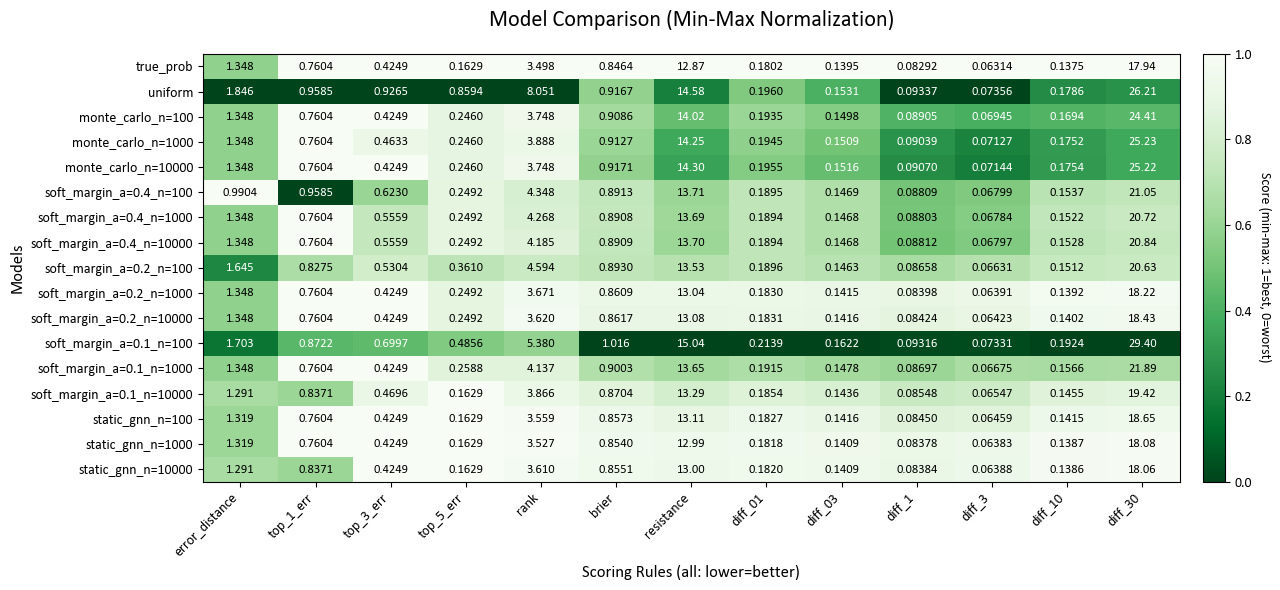

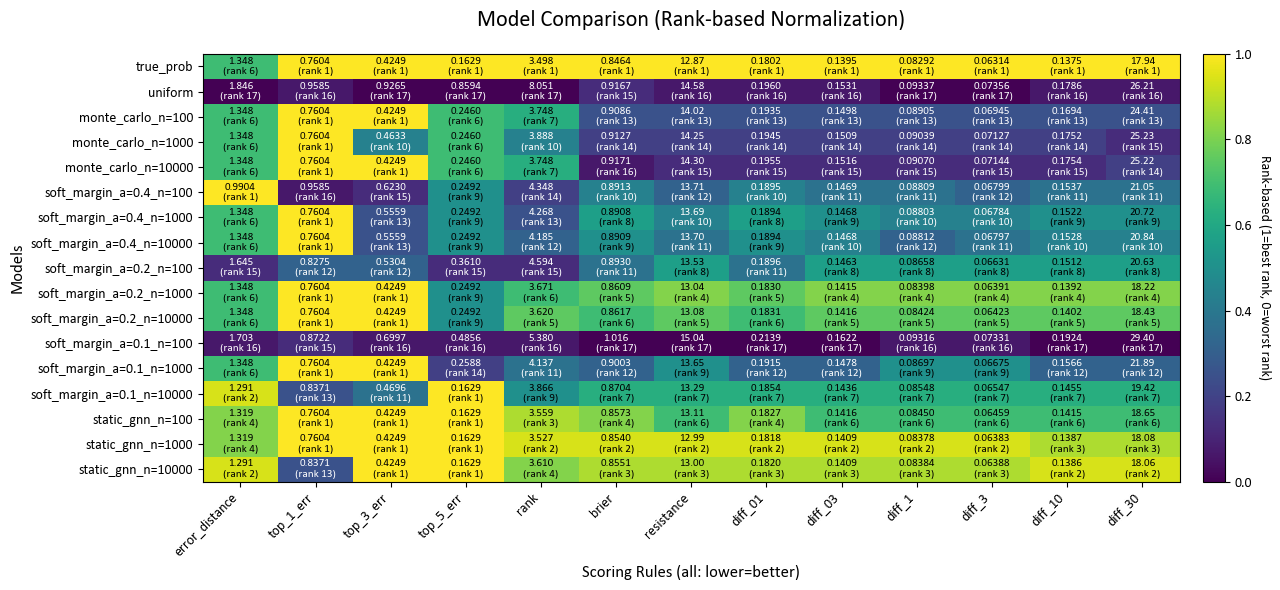

In [16]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[0], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

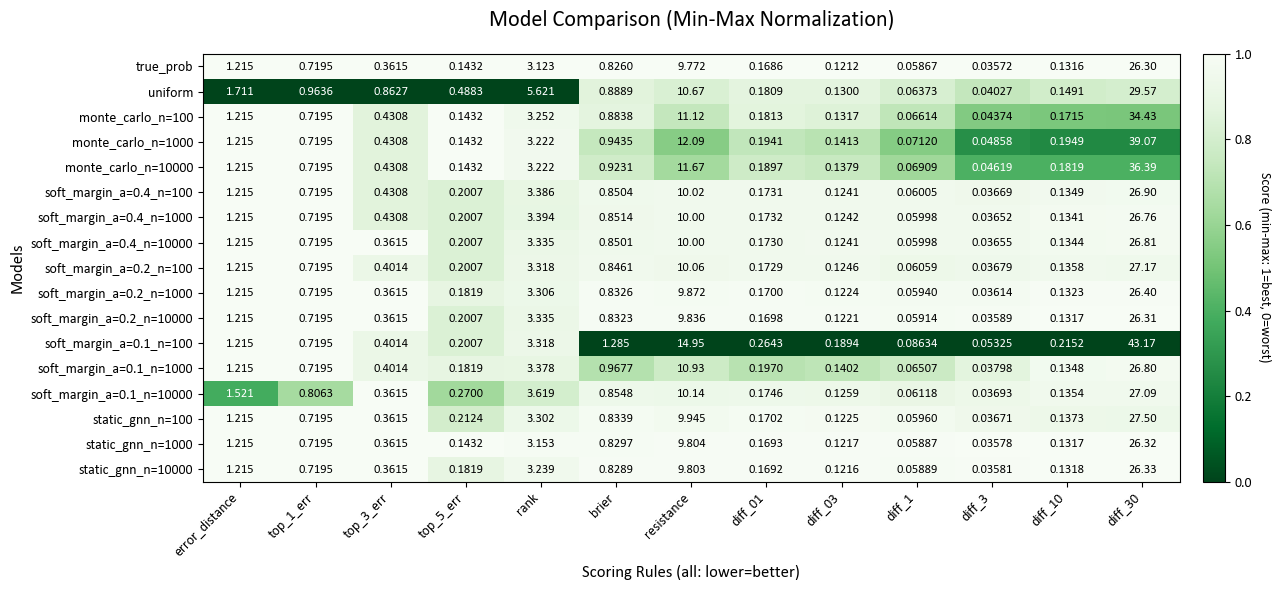

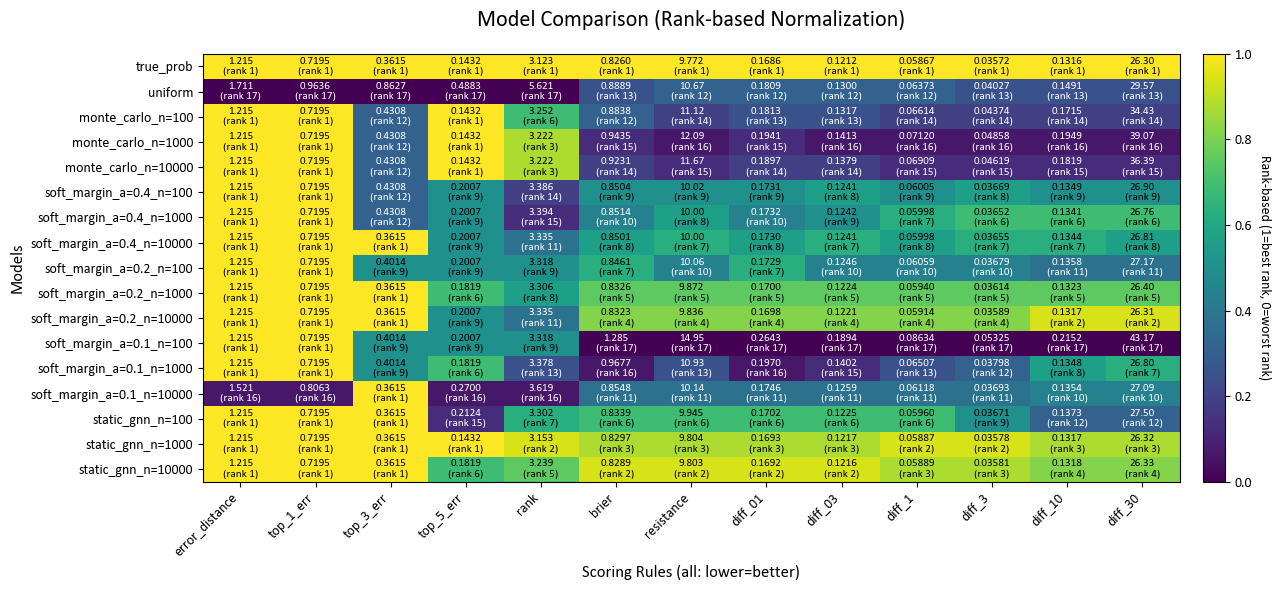

In [17]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[1], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

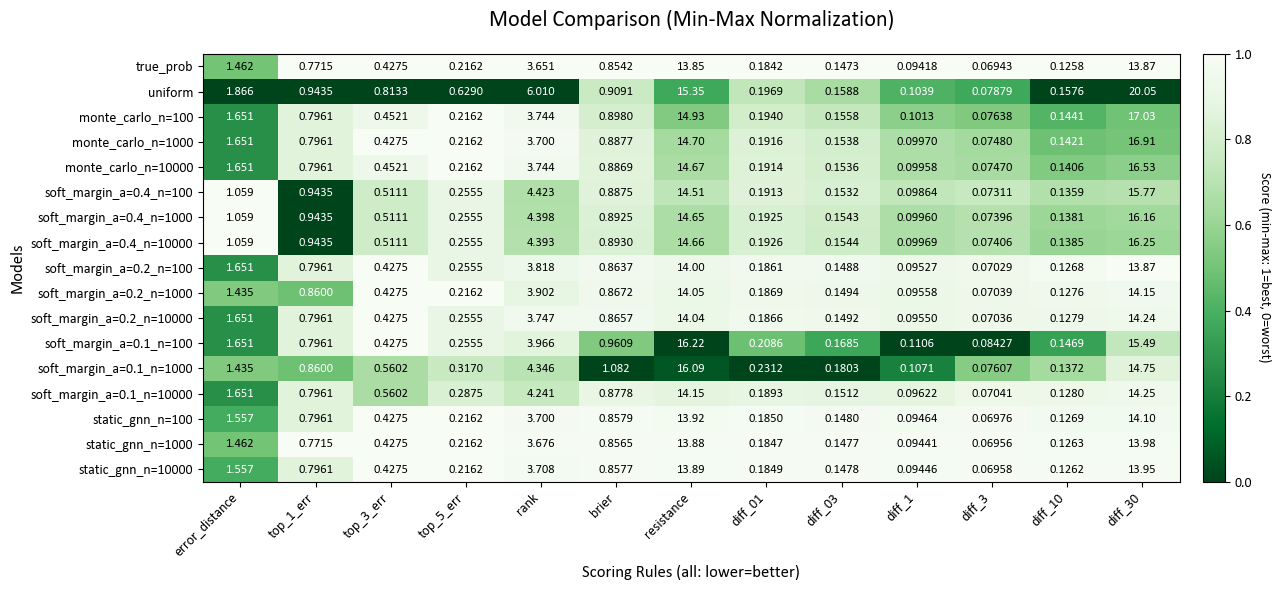

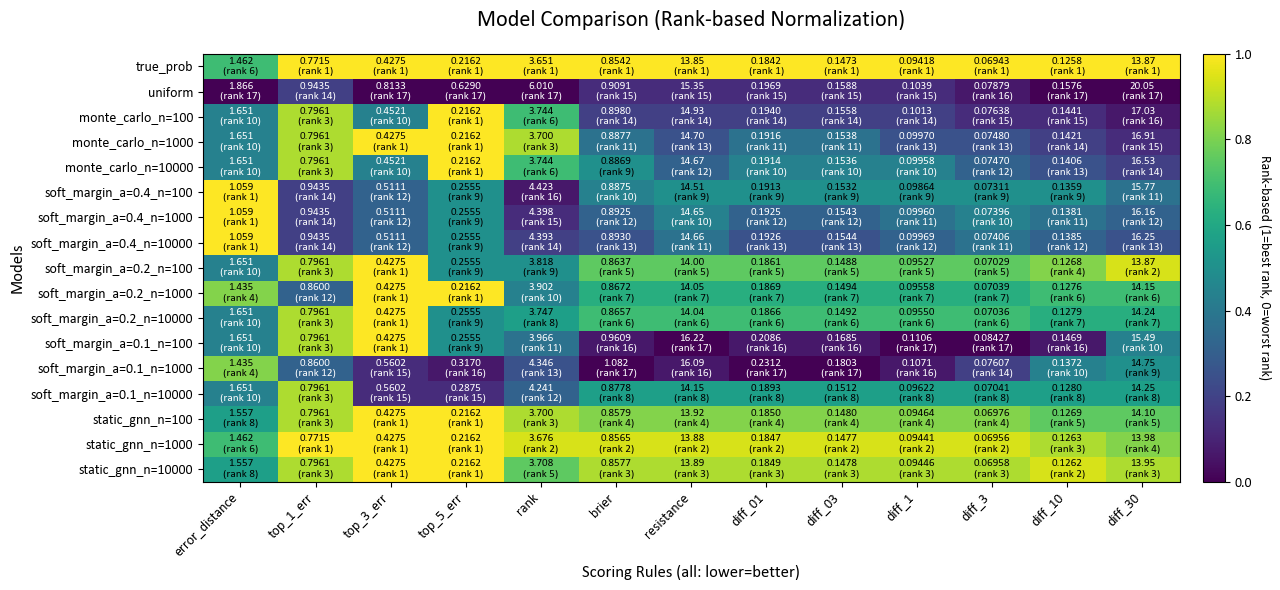

In [18]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[2], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

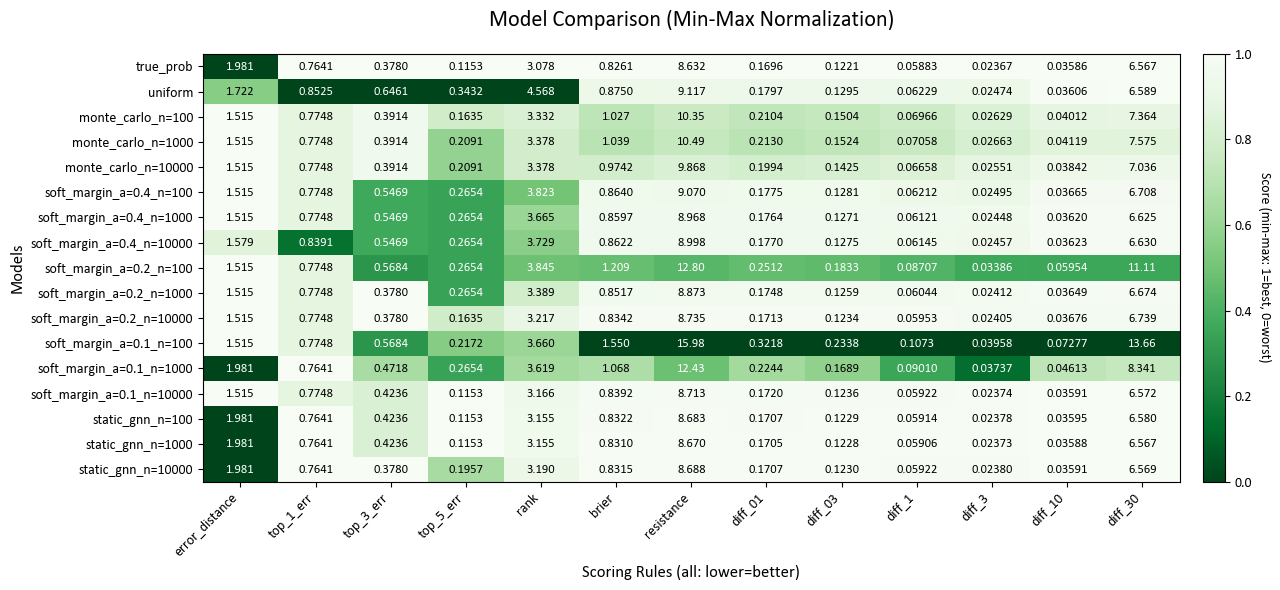

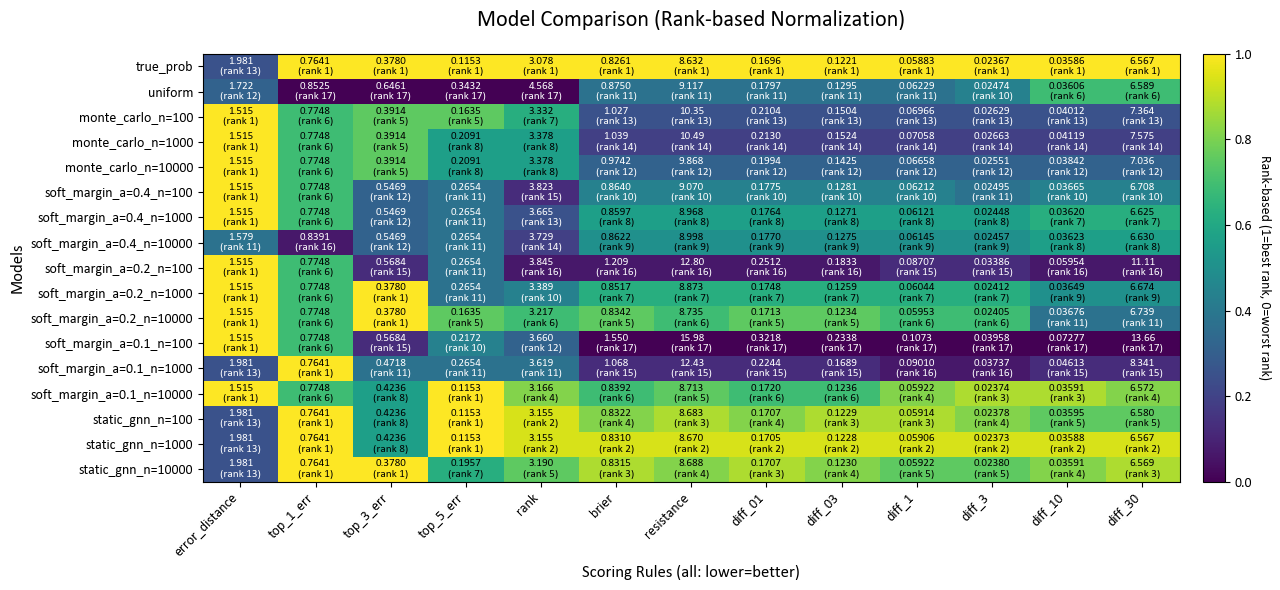

In [19]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[3], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

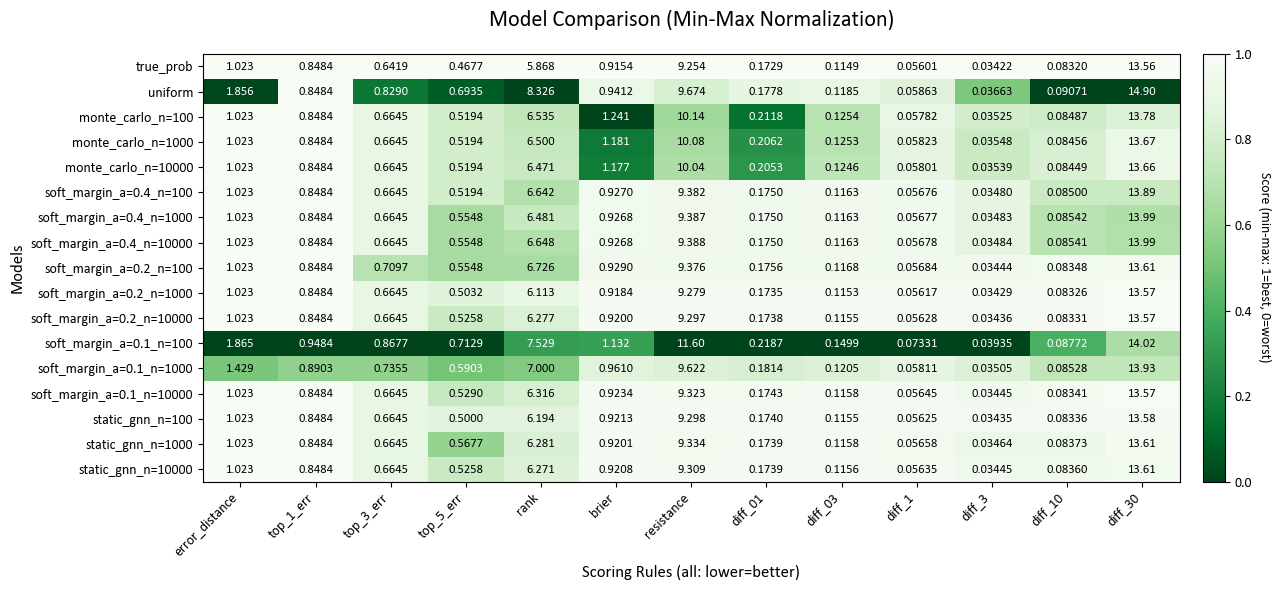

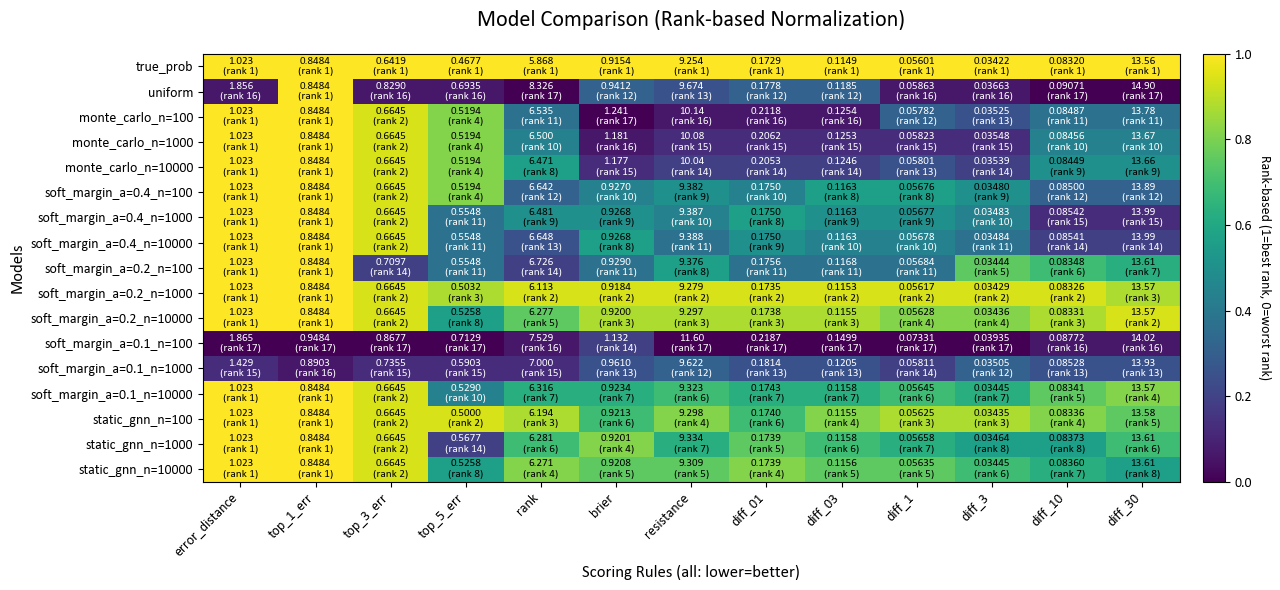

In [20]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[4], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

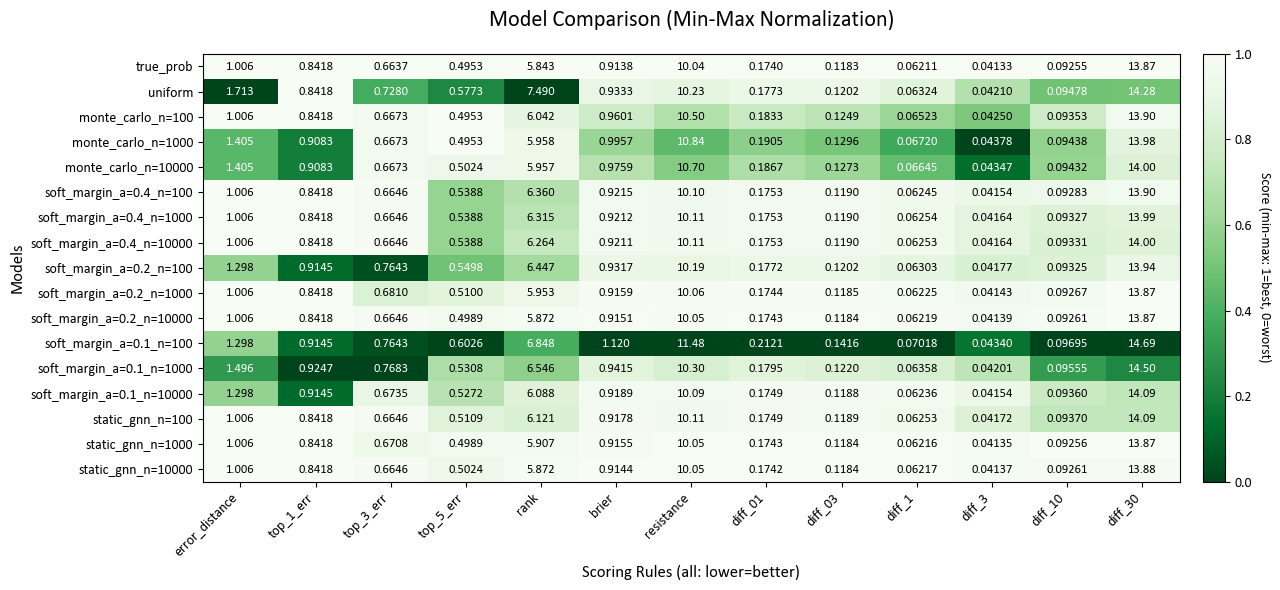

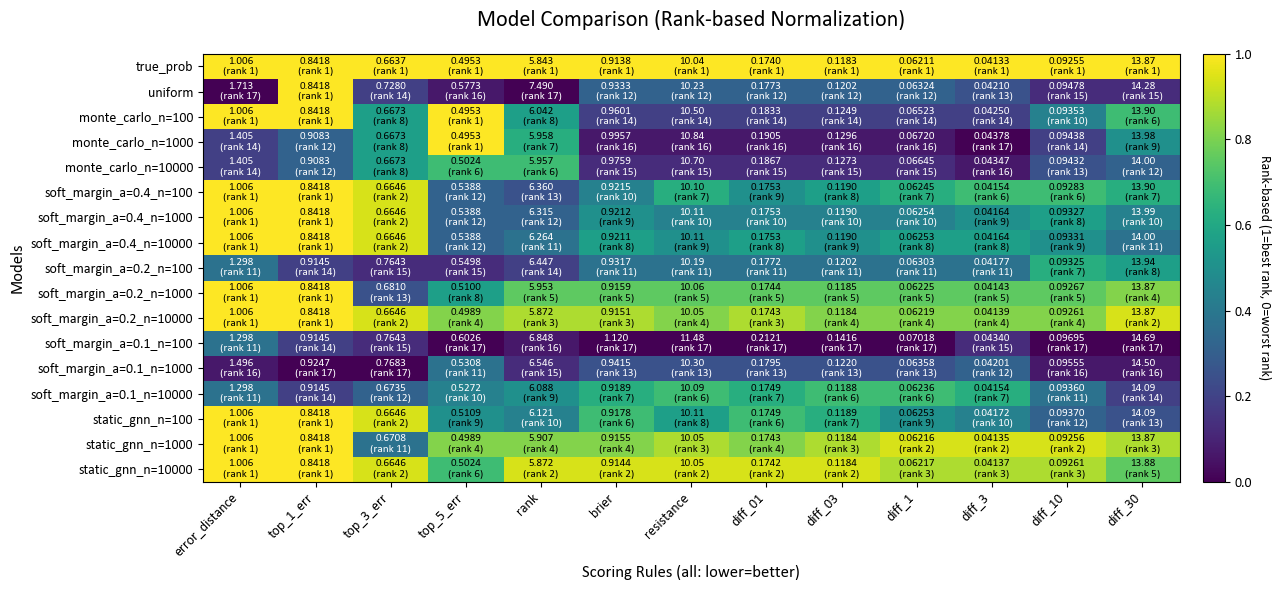

In [21]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[5], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

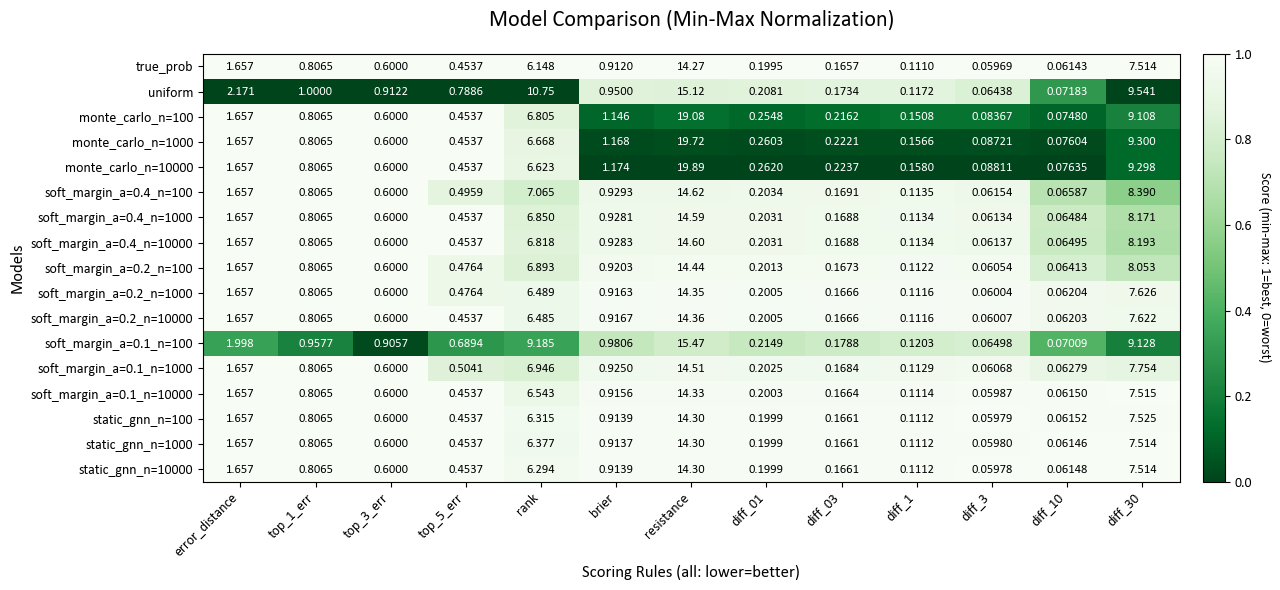

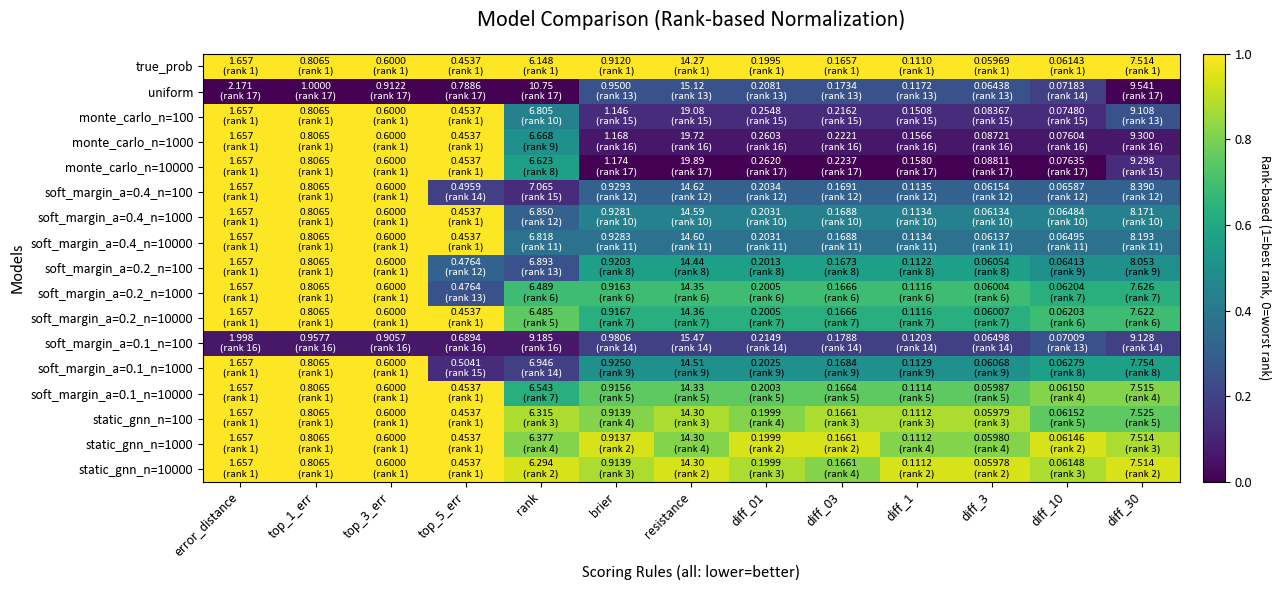

In [22]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[6], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

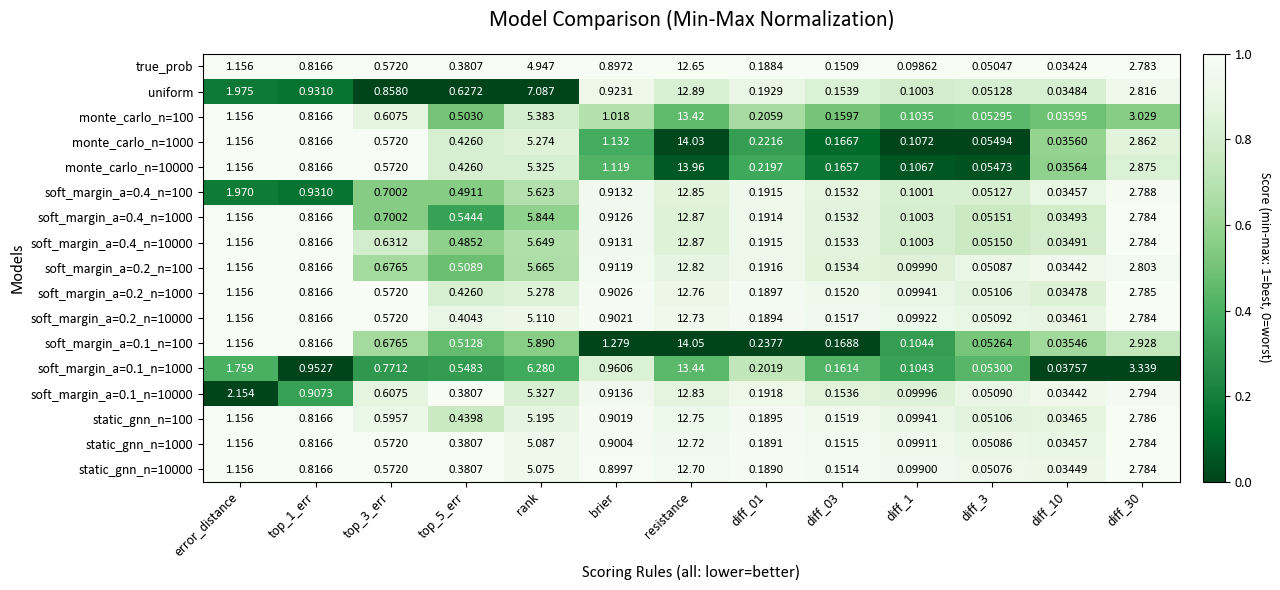

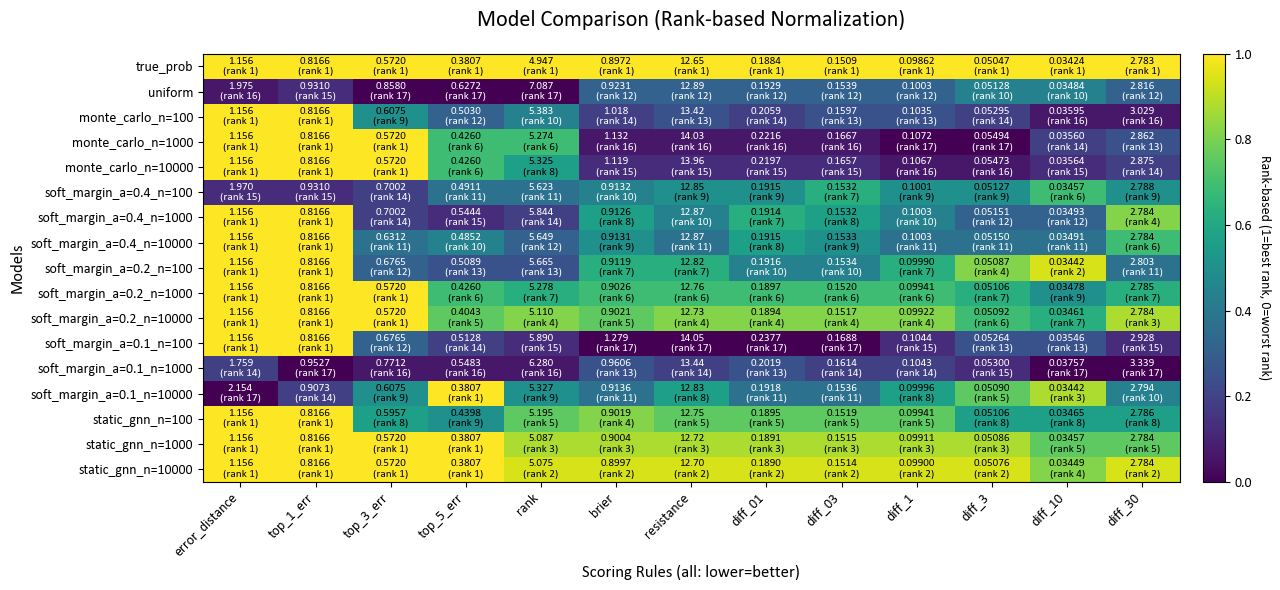

In [23]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[7], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

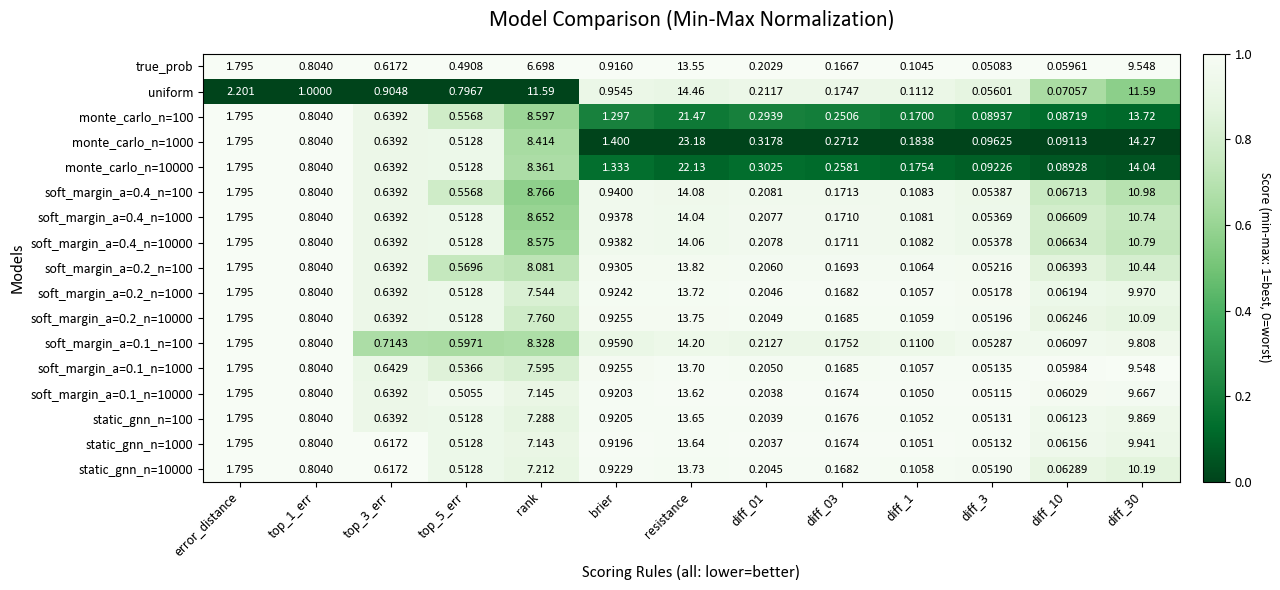

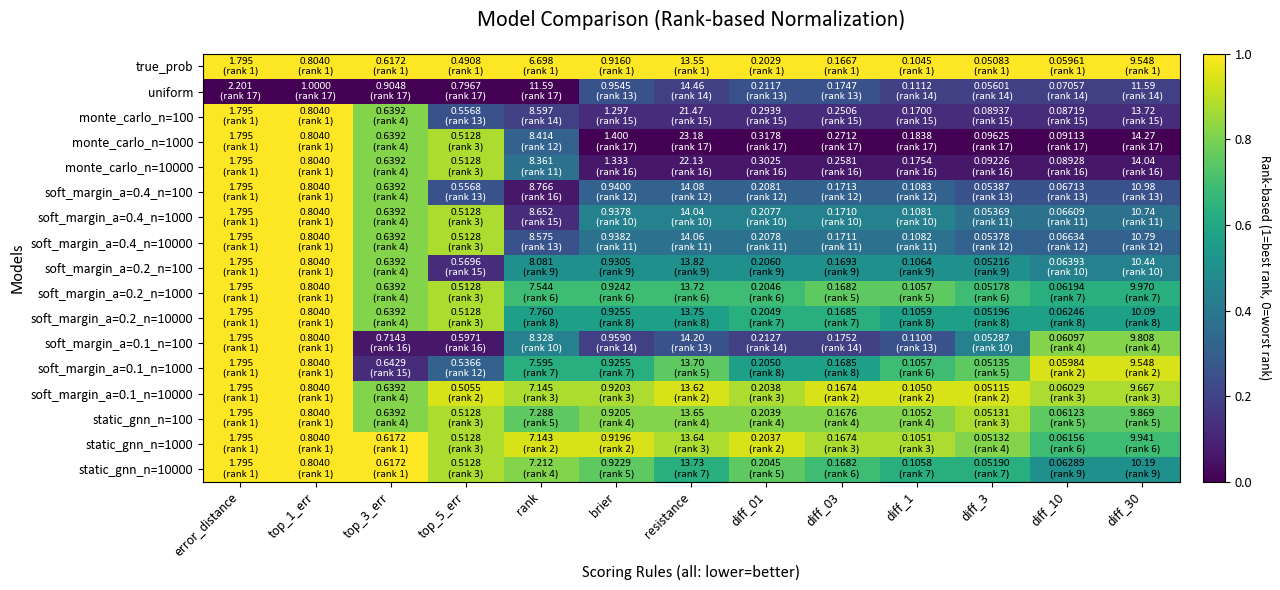

In [24]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[8], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

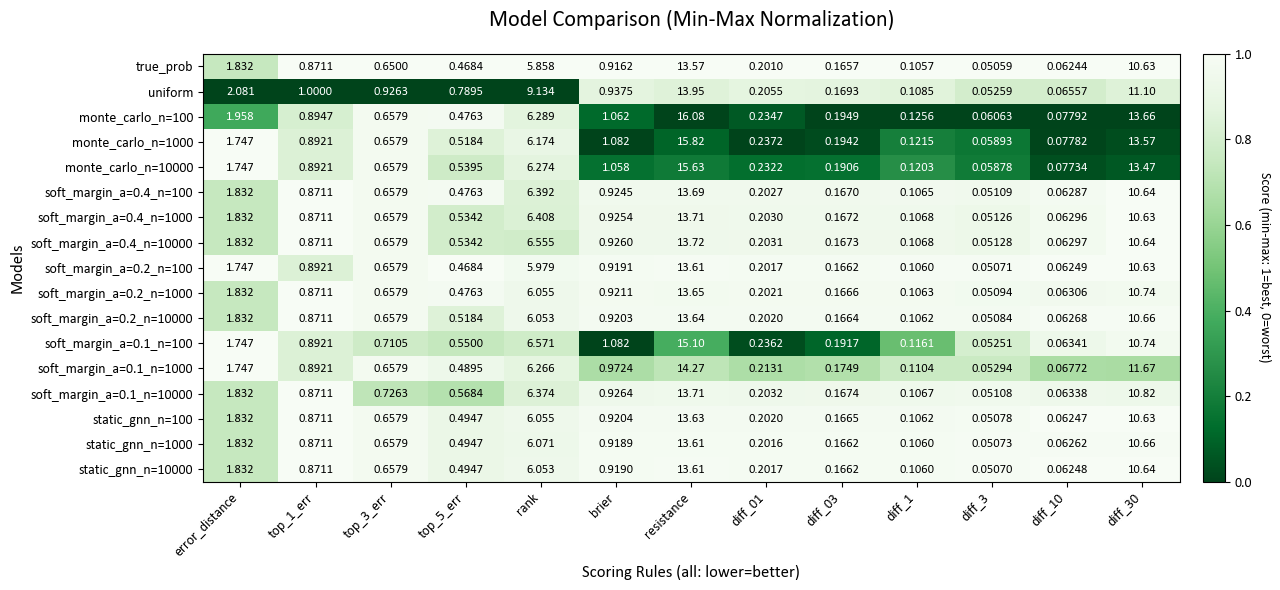

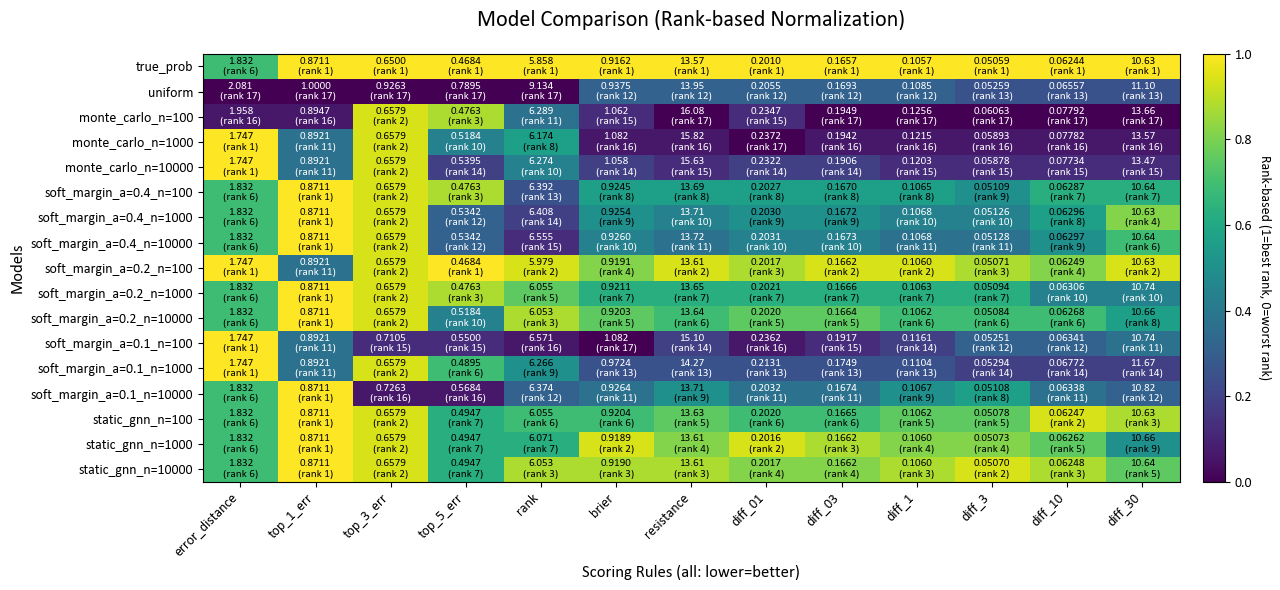

In [25]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[9], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

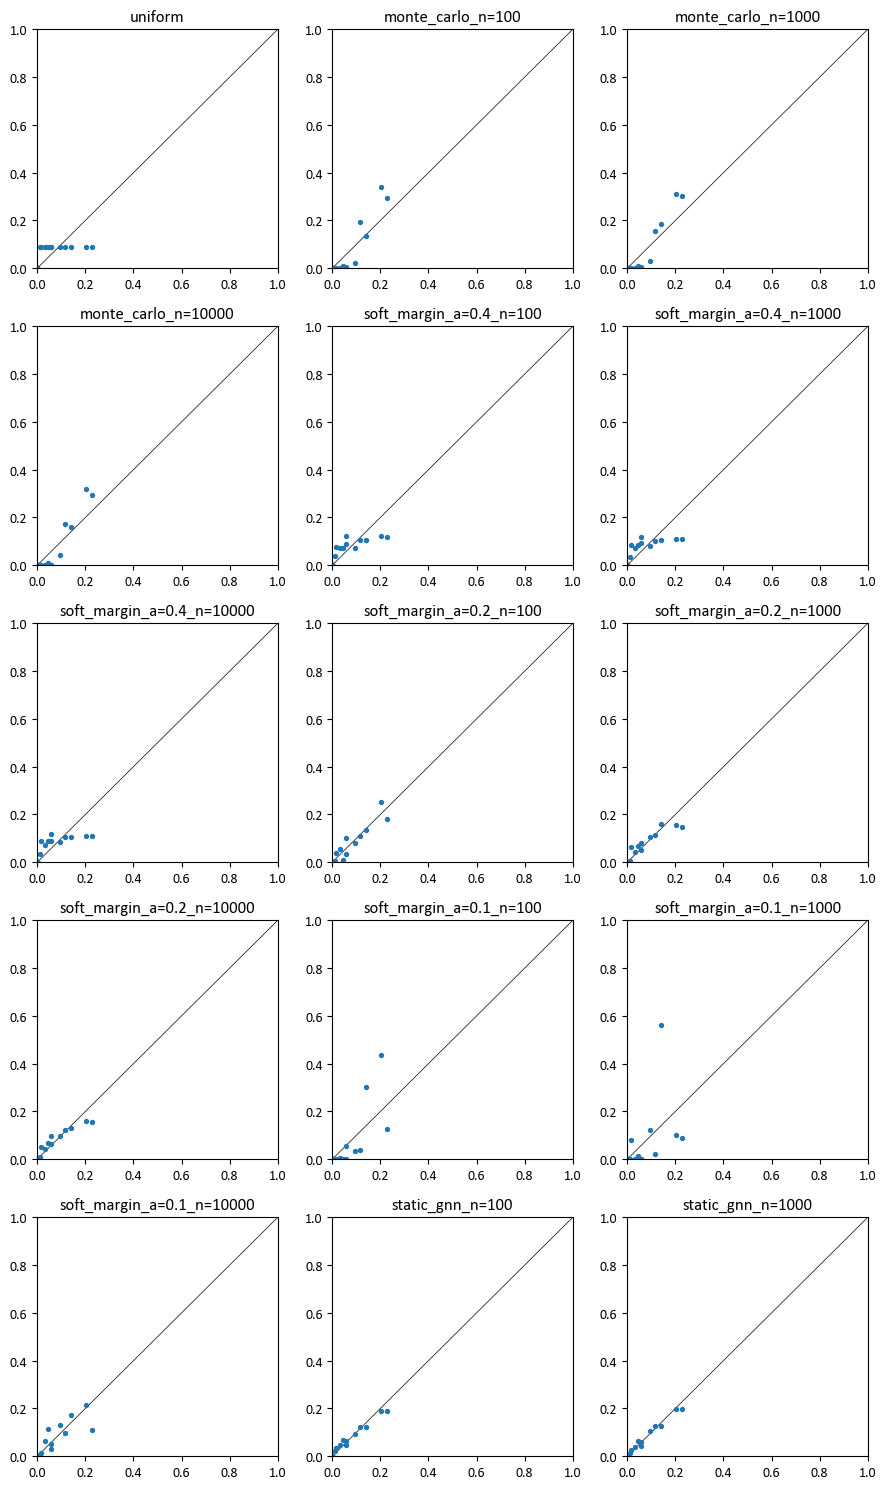

In [26]:
df = dfs[2]

fig, axs = plt.subplots(5, 3, figsize=(9,15))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

### Example run 2 for paper

In [27]:
model_columns = ['true_prob', 'monte_carlo_n=1000', 
    'soft_margin_a=0.2_n=1000', 'static_gnn_n=10000', 'soft_margin_a=0.1_n=10000'
]

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_85072\943351551.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


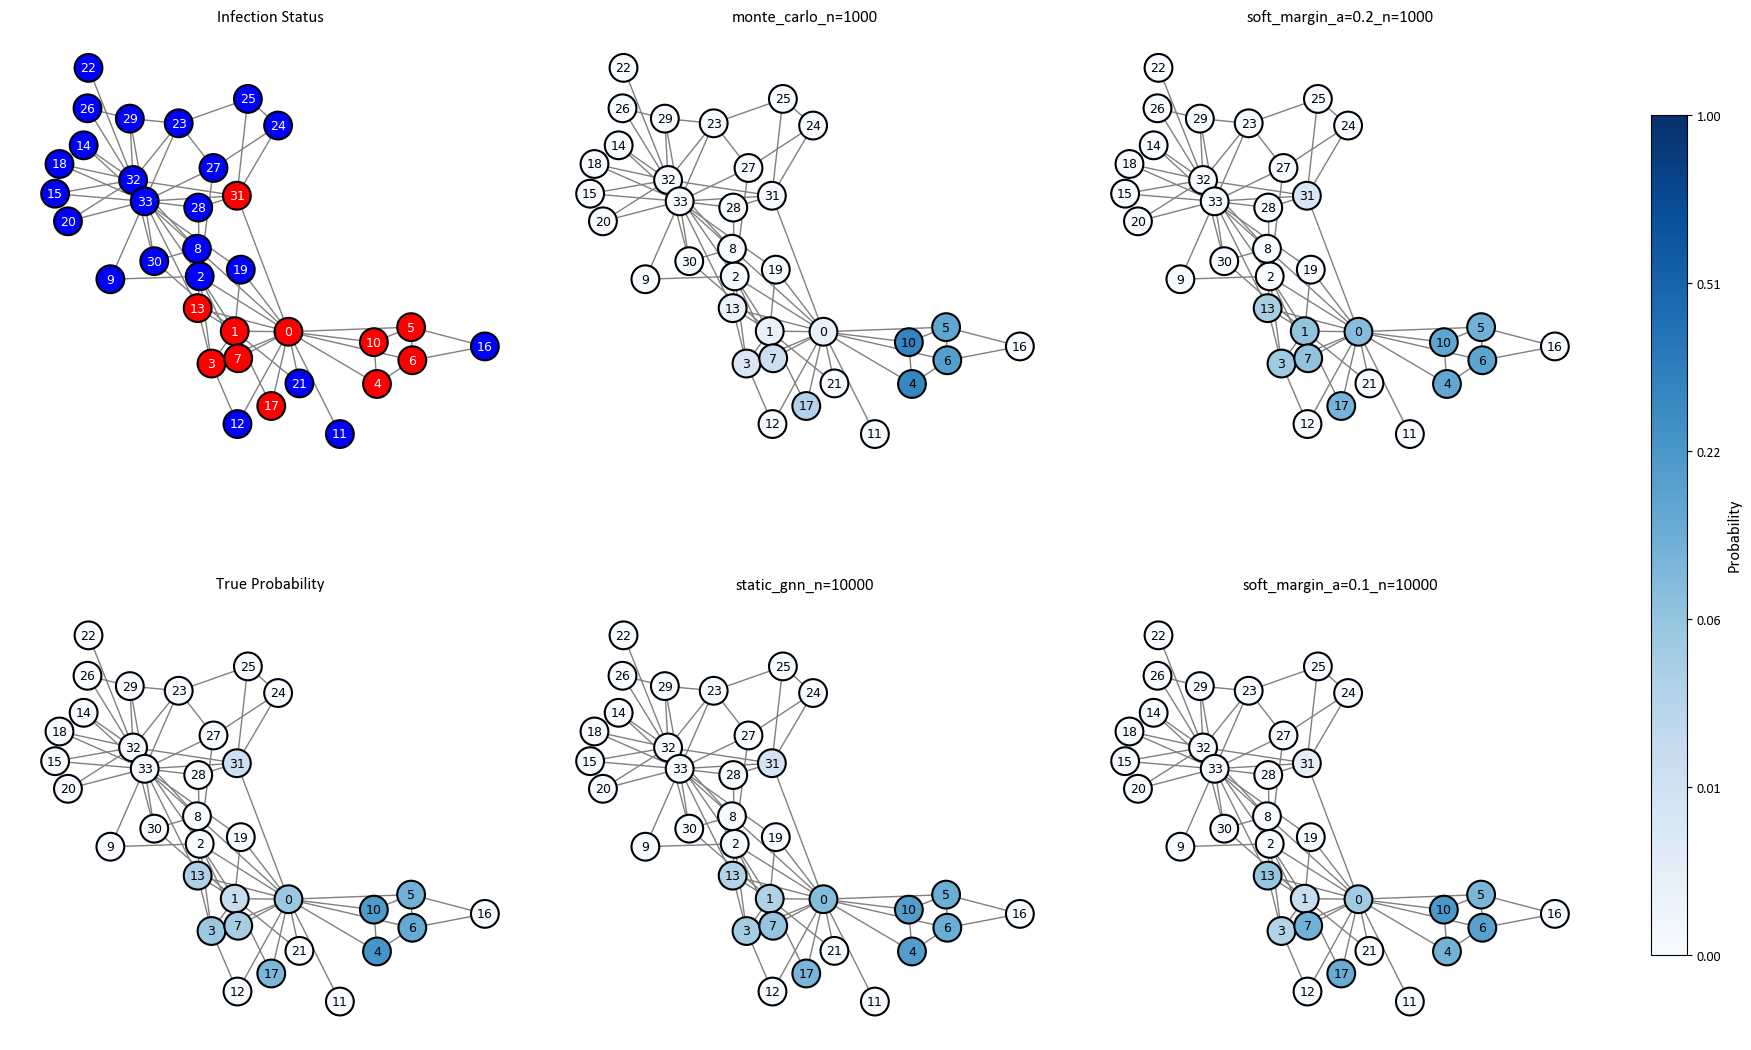

In [28]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[2]
models_to_plot = model_columns[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/3  # Change this value as needed

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = 0 if i <= 2 else 1  # 0 for first two models (top row), 1 for last two (bottom row)
    col = 1 if i % 2 == 1 else 2  # 1 for odd i (left), 2 for even i (right)
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
plt.show()

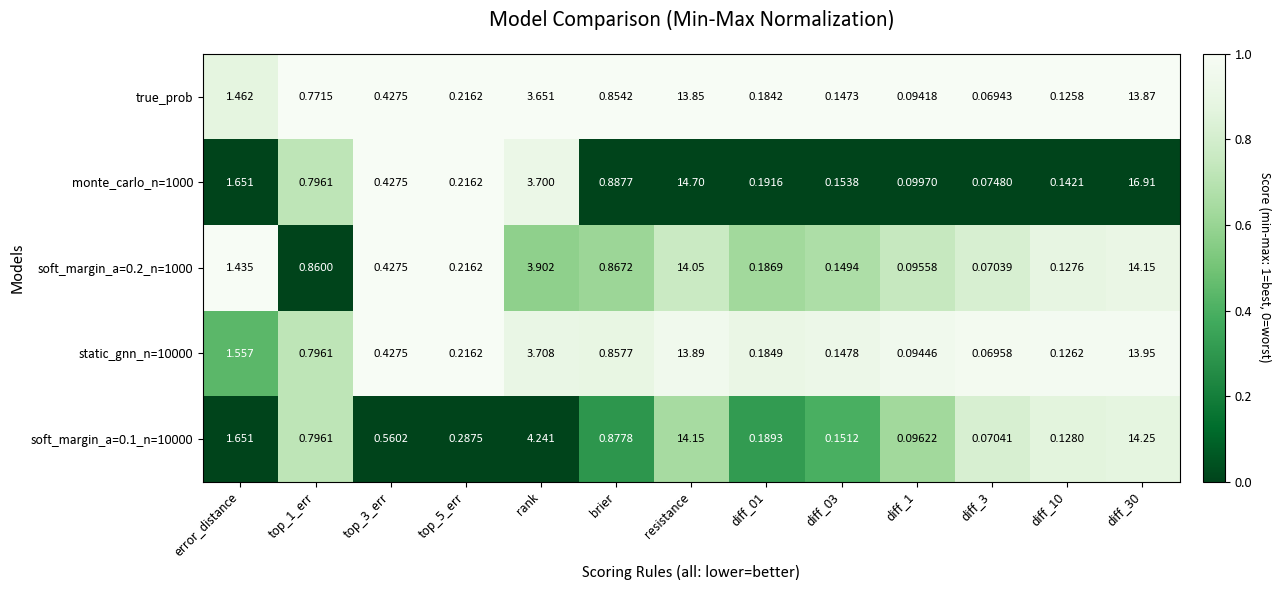

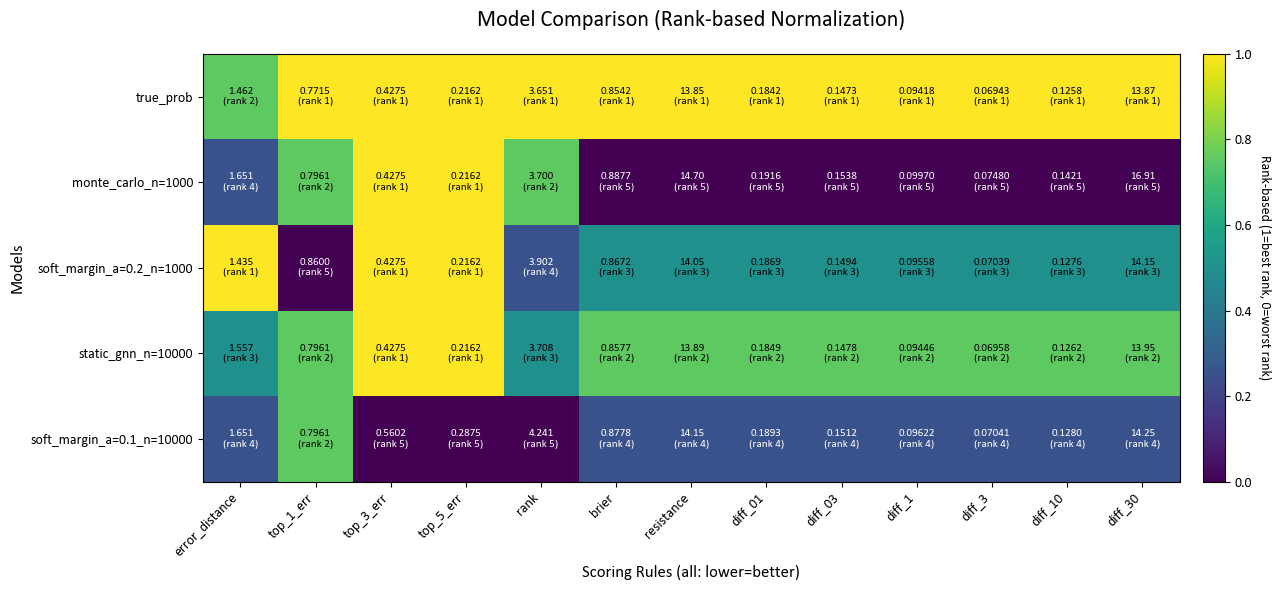

In [29]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[2], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

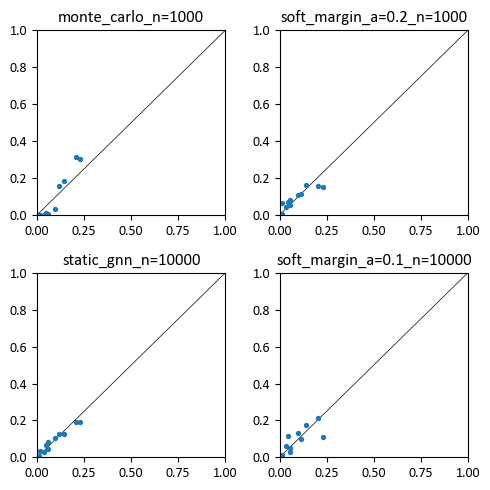

In [30]:
df = dfs[2]

fig, axs = plt.subplots(2, 2, figsize=(5,5))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

### Example run 1 for paper

In [31]:
model_columns = ['true_prob', 'monte_carlo_n=10000', 
    'soft_margin_a=0.4_n=10000', 'static_gnn_n=10000', 'soft_margin_a=0.2_n=10000'
]

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_85072\1831431318.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


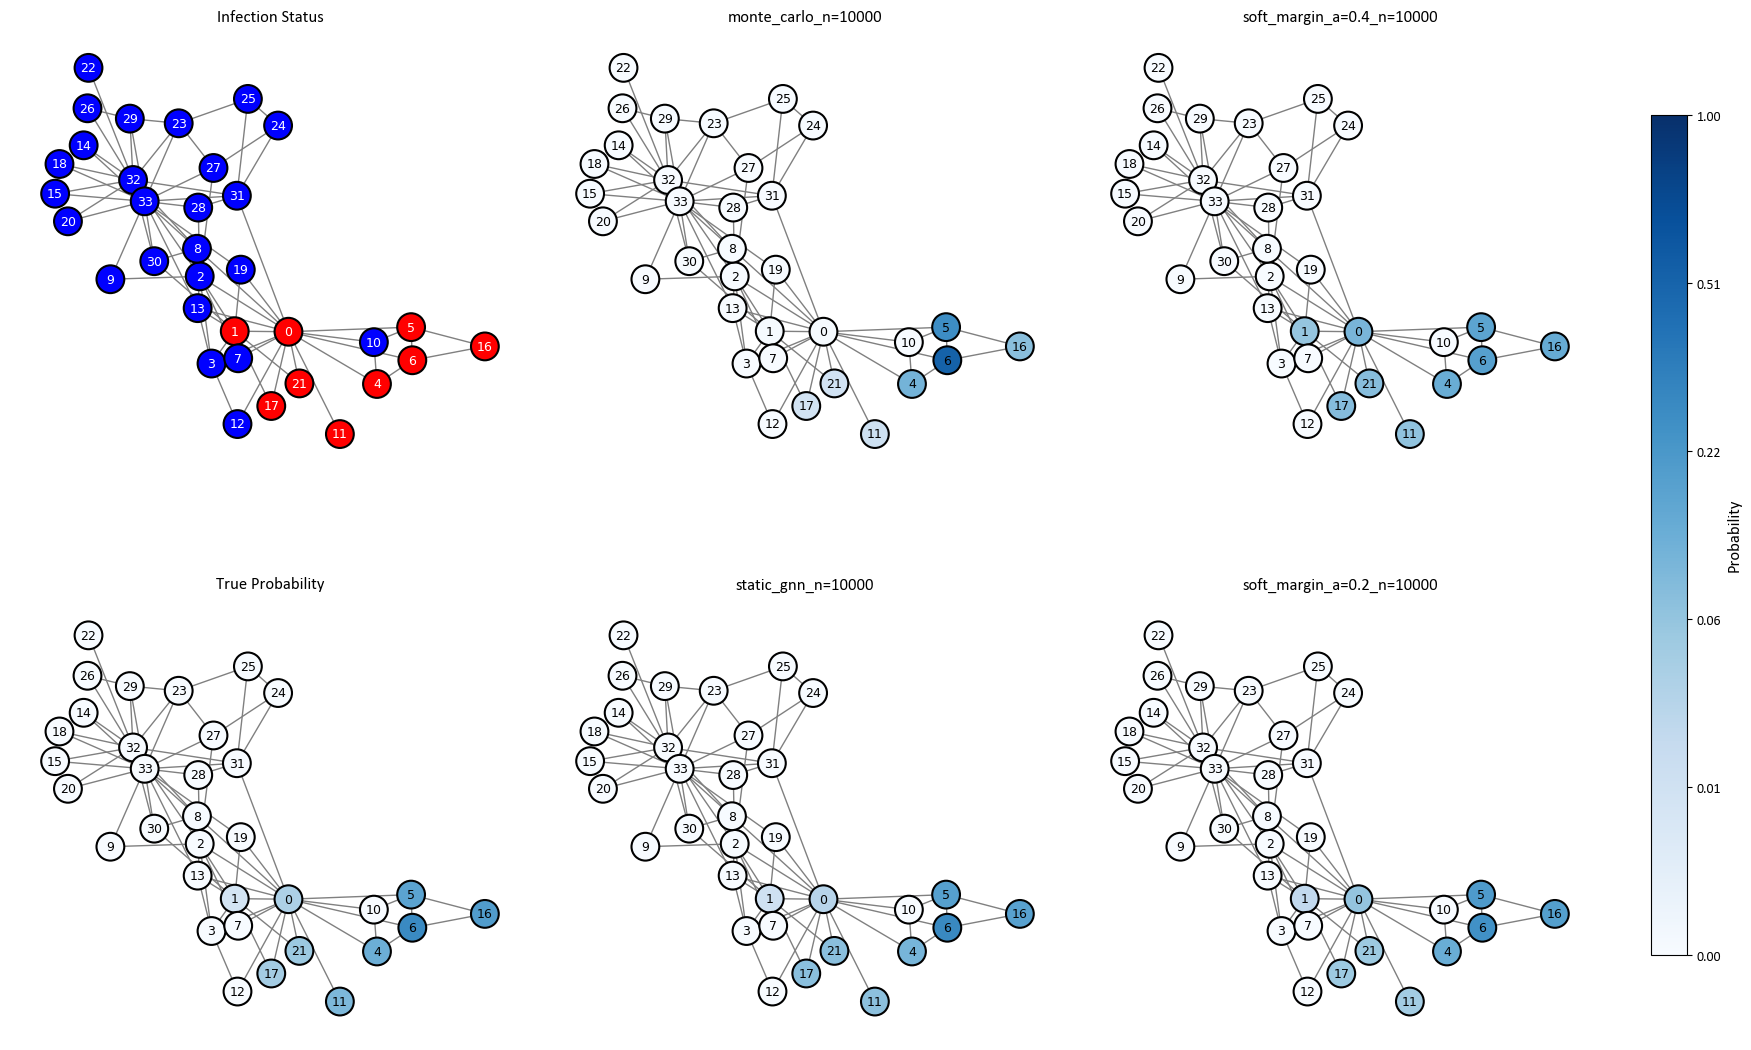

In [32]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[1]
models_to_plot = model_columns[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/3  # Change this value as needed

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = 0 if i <= 2 else 1  # 0 for first two models (top row), 1 for last two (bottom row)
    col = 1 if i % 2 == 1 else 2  # 1 for odd i (left), 2 for even i (right)
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
plt.show()

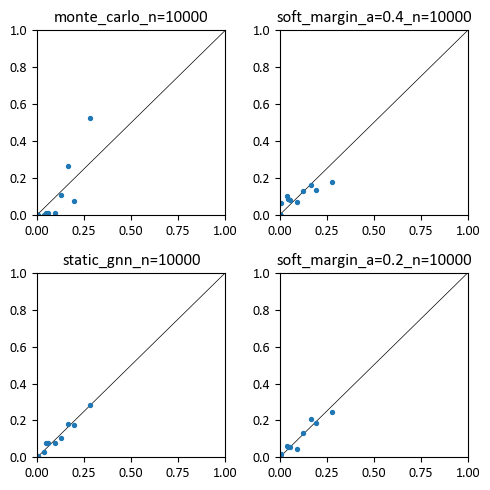

In [33]:
df = dfs[1]

fig, axs = plt.subplots(2, 2, figsize=(5,5))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

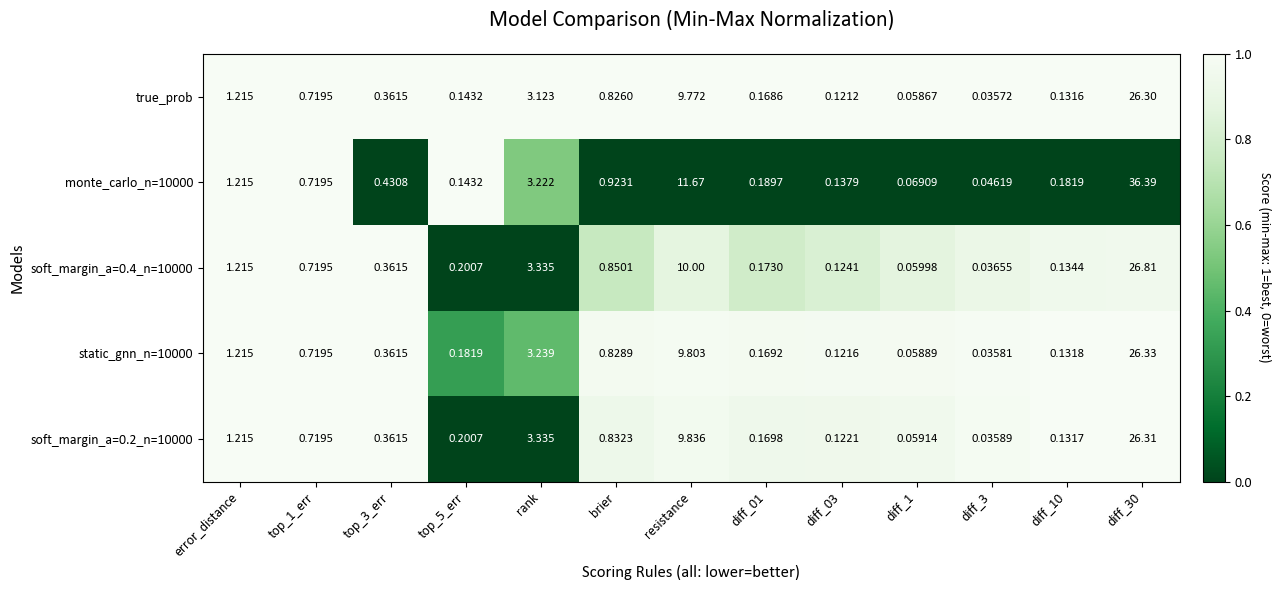

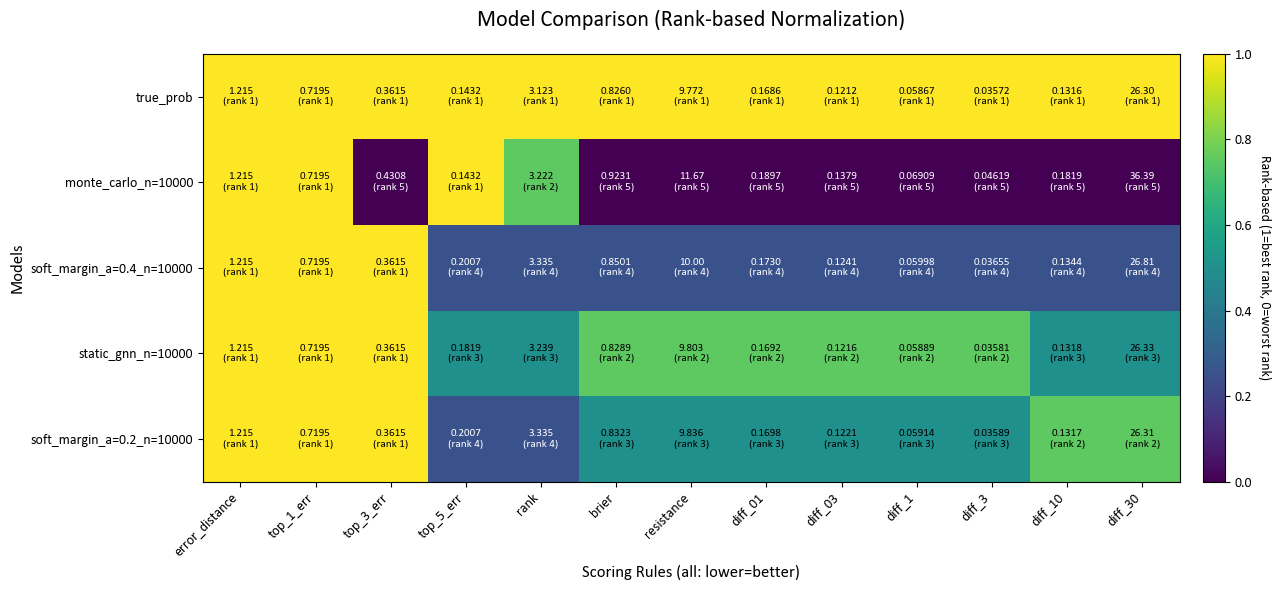

In [34]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[1], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

### Example run 4 for paper

In [35]:
model_columns = ['true_prob', 'monte_carlo_n=1000', 
    'soft_margin_a=0.2_n=1000', 'static_gnn_n=1000', 'soft_margin_a=0.1_n=10000'
]

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_85072\2391459856.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


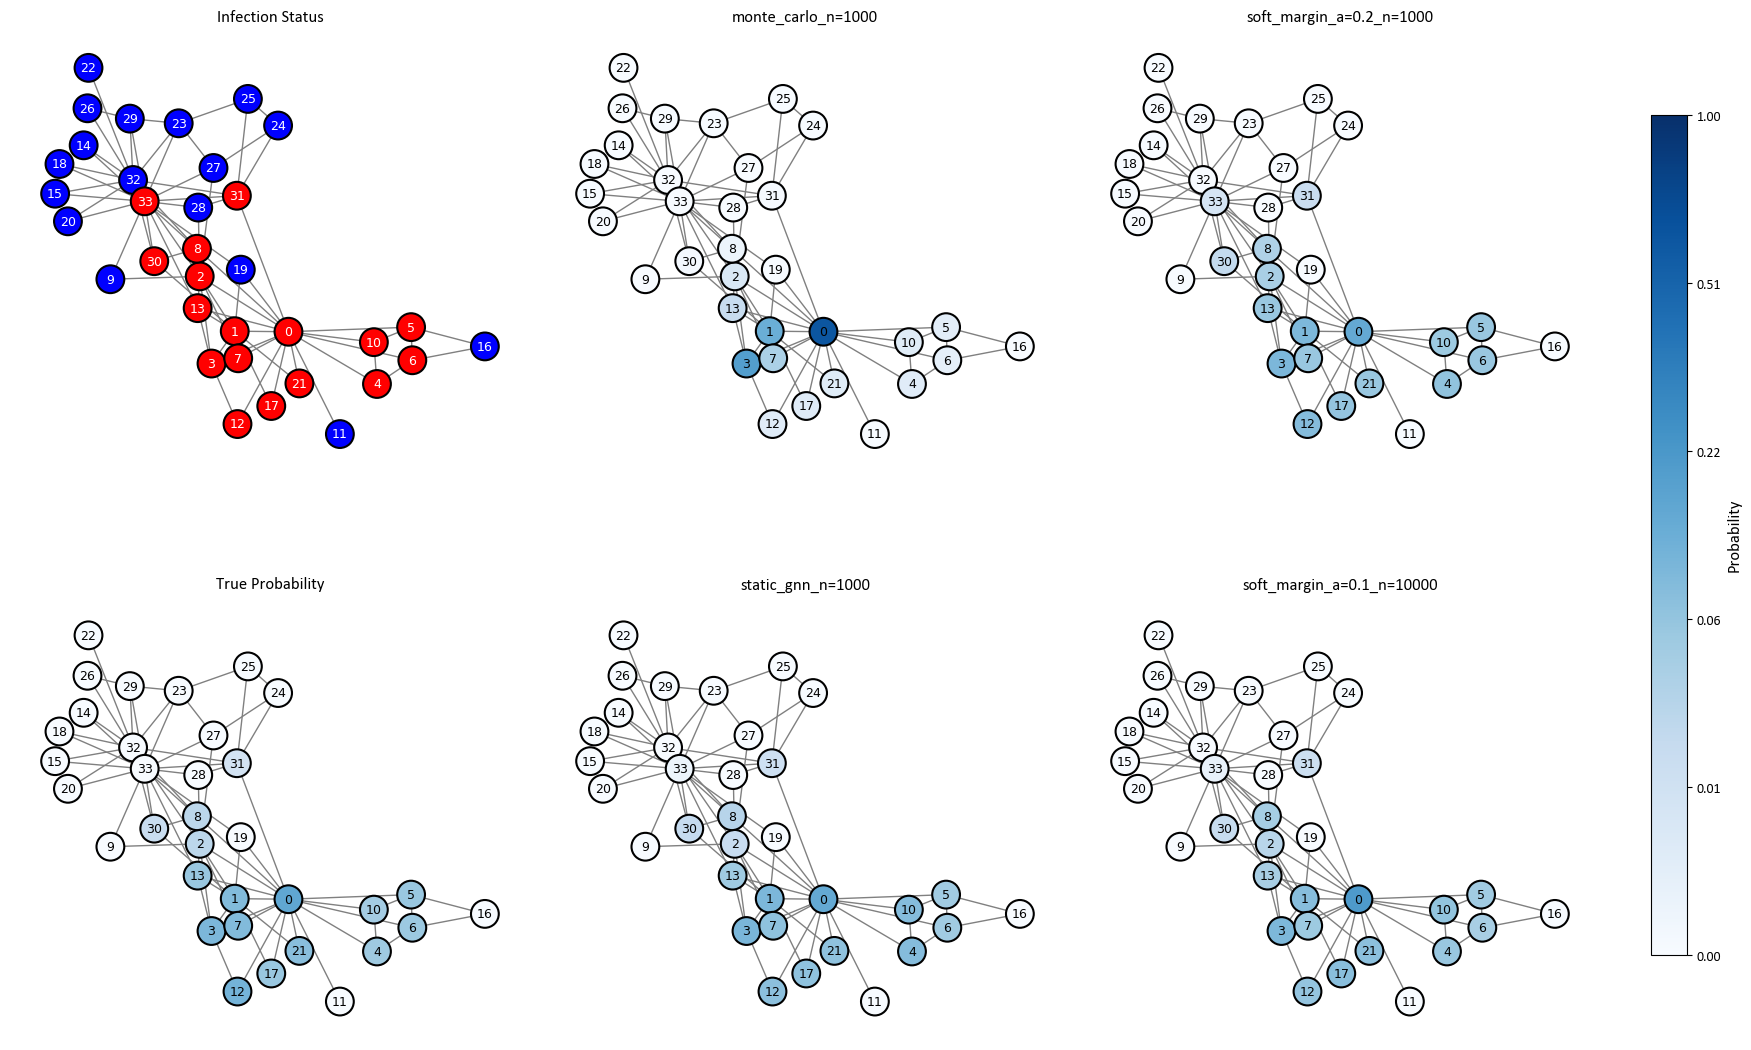

In [36]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[4]
models_to_plot = model_columns[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/3  # Change this value as needed

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = 0 if i <= 2 else 1  # 0 for first two models (top row), 1 for last two (bottom row)
    col = 1 if i % 2 == 1 else 2  # 1 for odd i (left), 2 for even i (right)
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
plt.show()

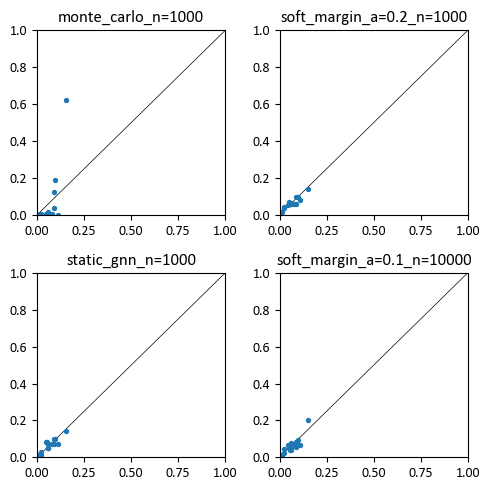

In [37]:
df = dfs[4]

fig, axs = plt.subplots(2, 2, figsize=(5,5))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

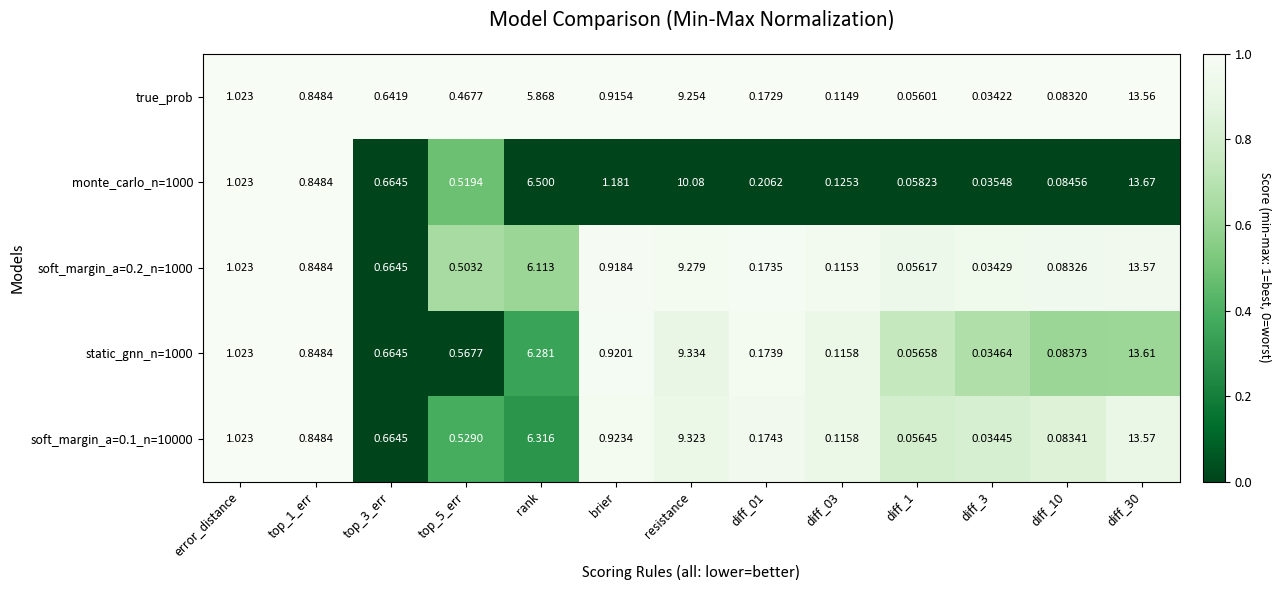

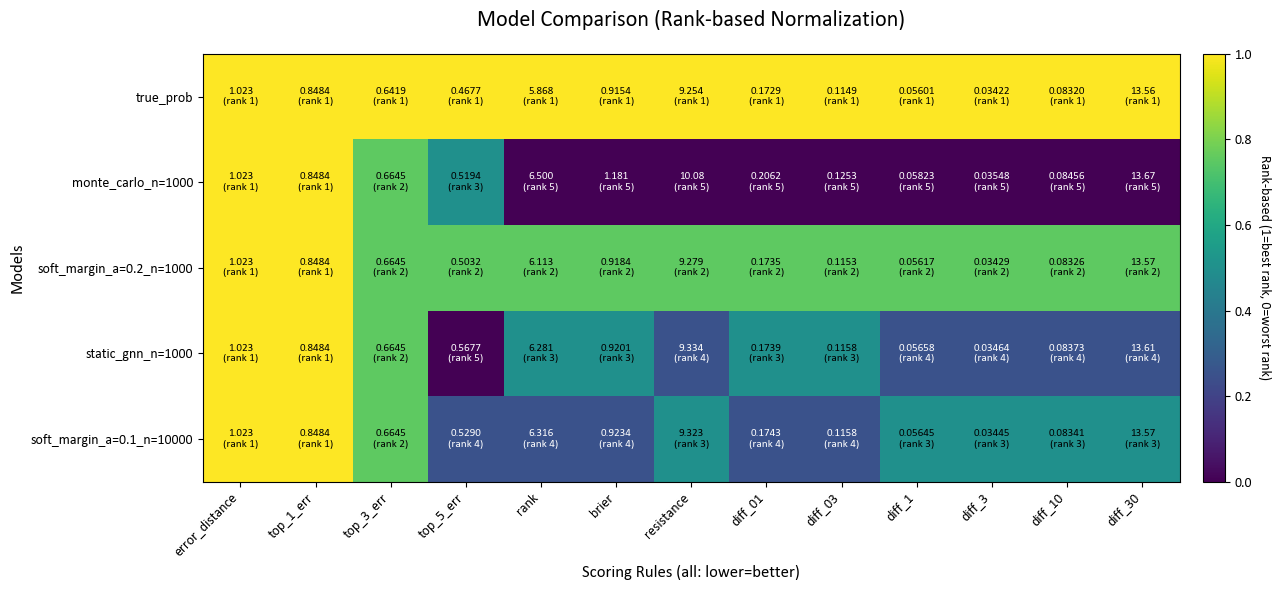

In [38]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[4], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

### Example run 1b for paper

In [39]:

# slightly modified model that has more probability mass on the left cluster
dfs[1]["soft_margin_a=0.1_n=1000_modified"] = dfs[1]["soft_margin_a=0.1_n=1000"]
#dfs[1].loc[6,"soft_margin_a=0.1_n=1000_modified"] = dfs[1].loc[6,"soft_margin_a=0.1_n=1000_modified"] - 0.01
dfs[1].loc[16,"soft_margin_a=0.1_n=1000_modified"] = dfs[1].loc[16,"soft_margin_a=0.1_n=1000_modified"] - 0.02
dfs[1].loc[11,"soft_margin_a=0.1_n=1000_modified"] = dfs[1].loc[11,"soft_margin_a=0.1_n=1000_modified"] + 0.02

# two point masses (with mass of cluster)
true_prob_cluster_4_5_6_16 = dfs[1][dfs[1]["node"].isin([4,5,6,16])].sum()["true_prob"]
true_prob_cluster_1_17_21 = dfs[1][dfs[1]["node"].isin([1,17,21])].sum()["true_prob"]
prob_11 = dfs[1][dfs[1]["node"]==11].sum()["true_prob"]
prob_0 = dfs[1][dfs[1]["node"]==0].sum()["true_prob"]
dfs[1]["point_masses"] = 0
dfs[1].loc[11,"point_masses"] = prob_11
dfs[1].loc[0,"point_masses"] = prob_0
dfs[1].loc[6,"point_masses"] = true_prob_cluster_4_5_6_16
dfs[1].loc[21,"point_masses"] = true_prob_cluster_1_17_21


# piecewise uniform distribution with correct probability mass on two main clusters
dfs[1]["piecewise_uniform"] = dfs[1]["true_prob"]
dfs[1].loc[4,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[5,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[6,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[16,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[1,"piecewise_uniform"] = true_prob_cluster_1_17_21/3
dfs[1].loc[17,"piecewise_uniform"] = true_prob_cluster_1_17_21/3
dfs[1].loc[21,"piecewise_uniform"] = true_prob_cluster_1_17_21/3
dfs[1].loc[11,"piecewise_uniform"]  = prob_11
dfs[1].loc[0,"piecewise_uniform"]  = prob_0

'''
dfs[1]["piecewise_uniform"] = dfs[1]["true_prob"]
dfs[1].loc[4,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[5,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[6,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[16,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[1,"piecewise_uniform"] = (true_prob_cluster_1_17_21 + prob_0)/4
dfs[1].loc[17,"piecewise_uniform"] = (true_prob_cluster_1_17_21 + prob_0)/4
dfs[1].loc[21,"piecewise_uniform"] = (true_prob_cluster_1_17_21 + prob_0)/4
dfs[1].loc[11,"piecewise_uniform"]  = prob_11
dfs[1].loc[0,"piecewise_uniform"]  = (true_prob_cluster_1_17_21 + prob_0)/4
'''

display(dfs[1]["point_masses"].sum(), dfs[1]["piecewise_uniform"].sum())

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_85072\1239231618.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0938967136150234' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  dfs[1].loc[11,"point_masses"] = prob_11


np.float64(0.9999999999999996)

np.float64(0.9999999999999996)

In [40]:
model_columns = ['true_prob', 'static_gnn_n=10000', 'piecewise_uniform', 
    'soft_margin_a=0.1_n=1000', 'monte_carlo_n=1000' #, 'static_gnn_n=10000', 'soft_margin_a=0.4_n=10000'
] #sm0.2_10000, sm0.1_1000, gnn_10000, mcmc_1000

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_85072\2701632482.py:141: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


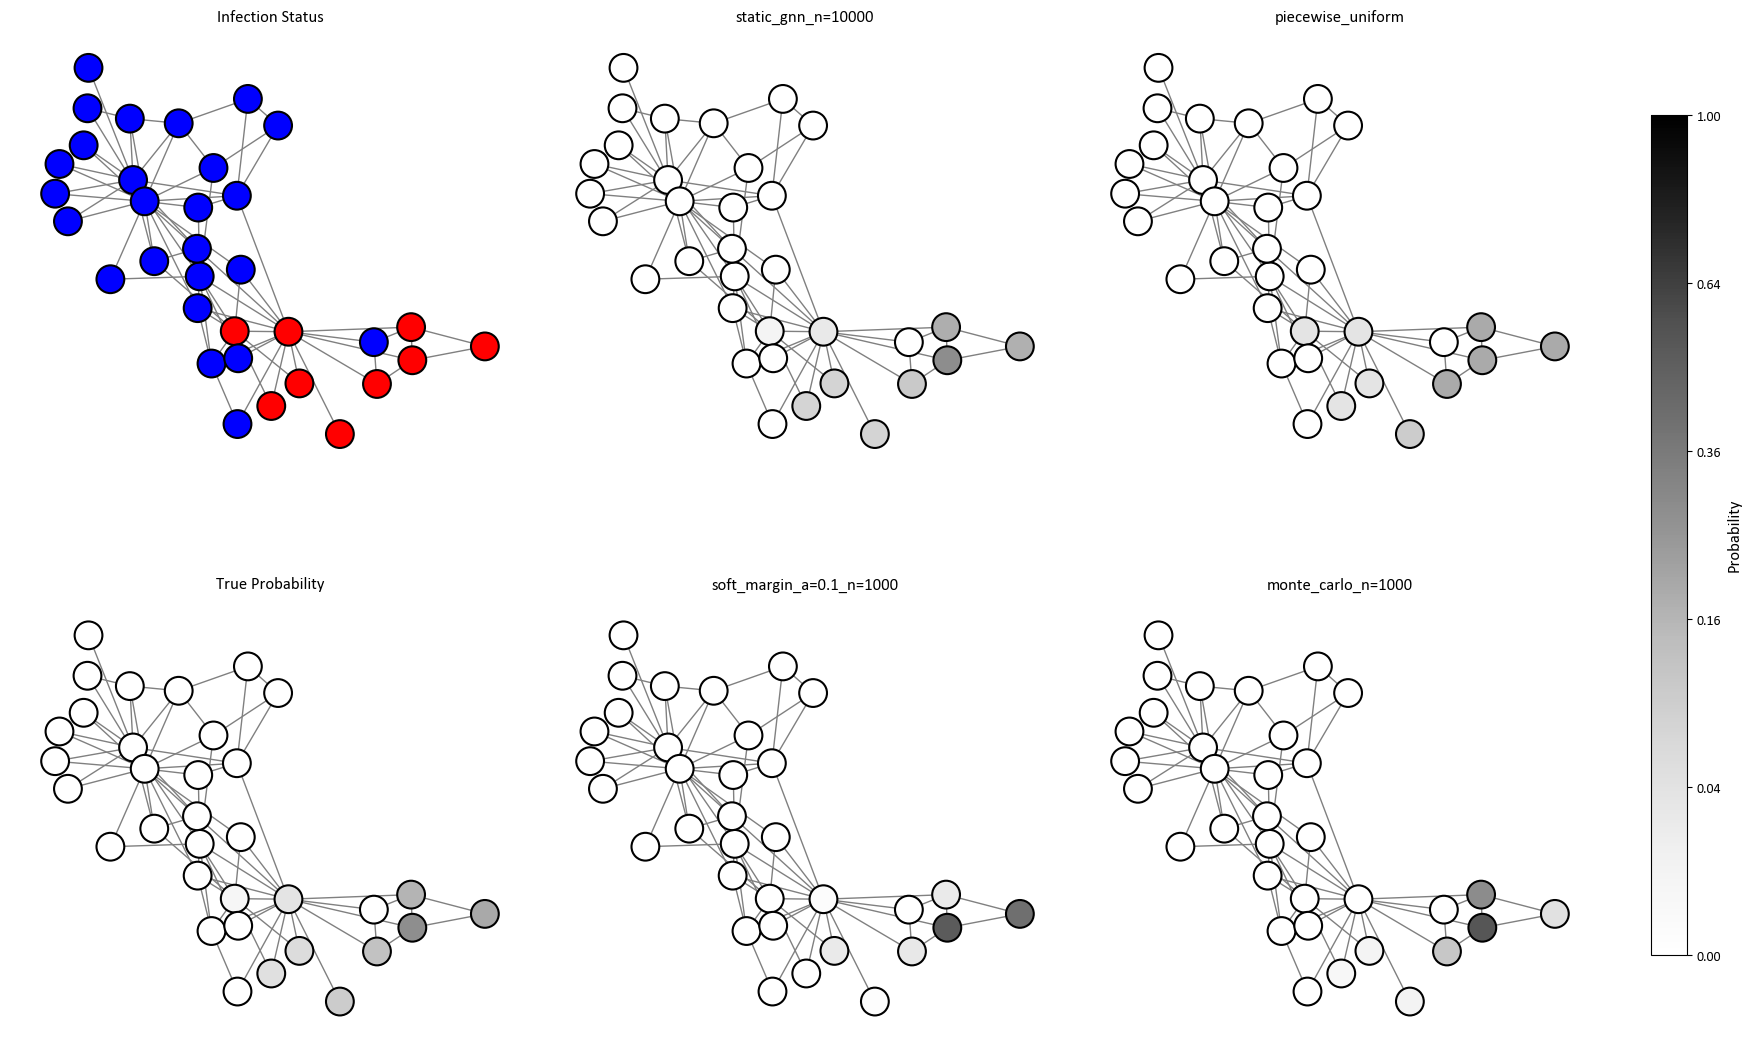

In [41]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[1]
models_to_plot = model_columns[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/2  # Change this value as needed

# colormap
cmap = plt.cm.Grays

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=False,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=cmap,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
#nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = 0 if i <= 2 else 1  # 0 for first two models (top row), 1 for last two (bottom row)
    col = 1 if i % 2 == 1 else 2  # 1 for odd i (left), 2 for even i (right)
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=cmap,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    #nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
#plt.savefig("../images/snapshot_run1_4models.pdf", dpi=1200)
plt.show()

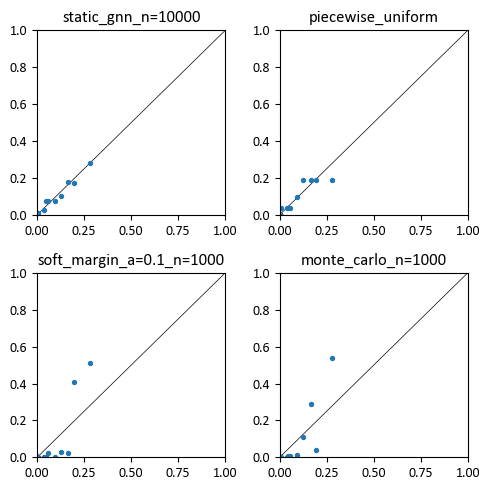

In [42]:
df = dfs[1]

fig, axs = plt.subplots(2, 2, figsize=(5,5))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

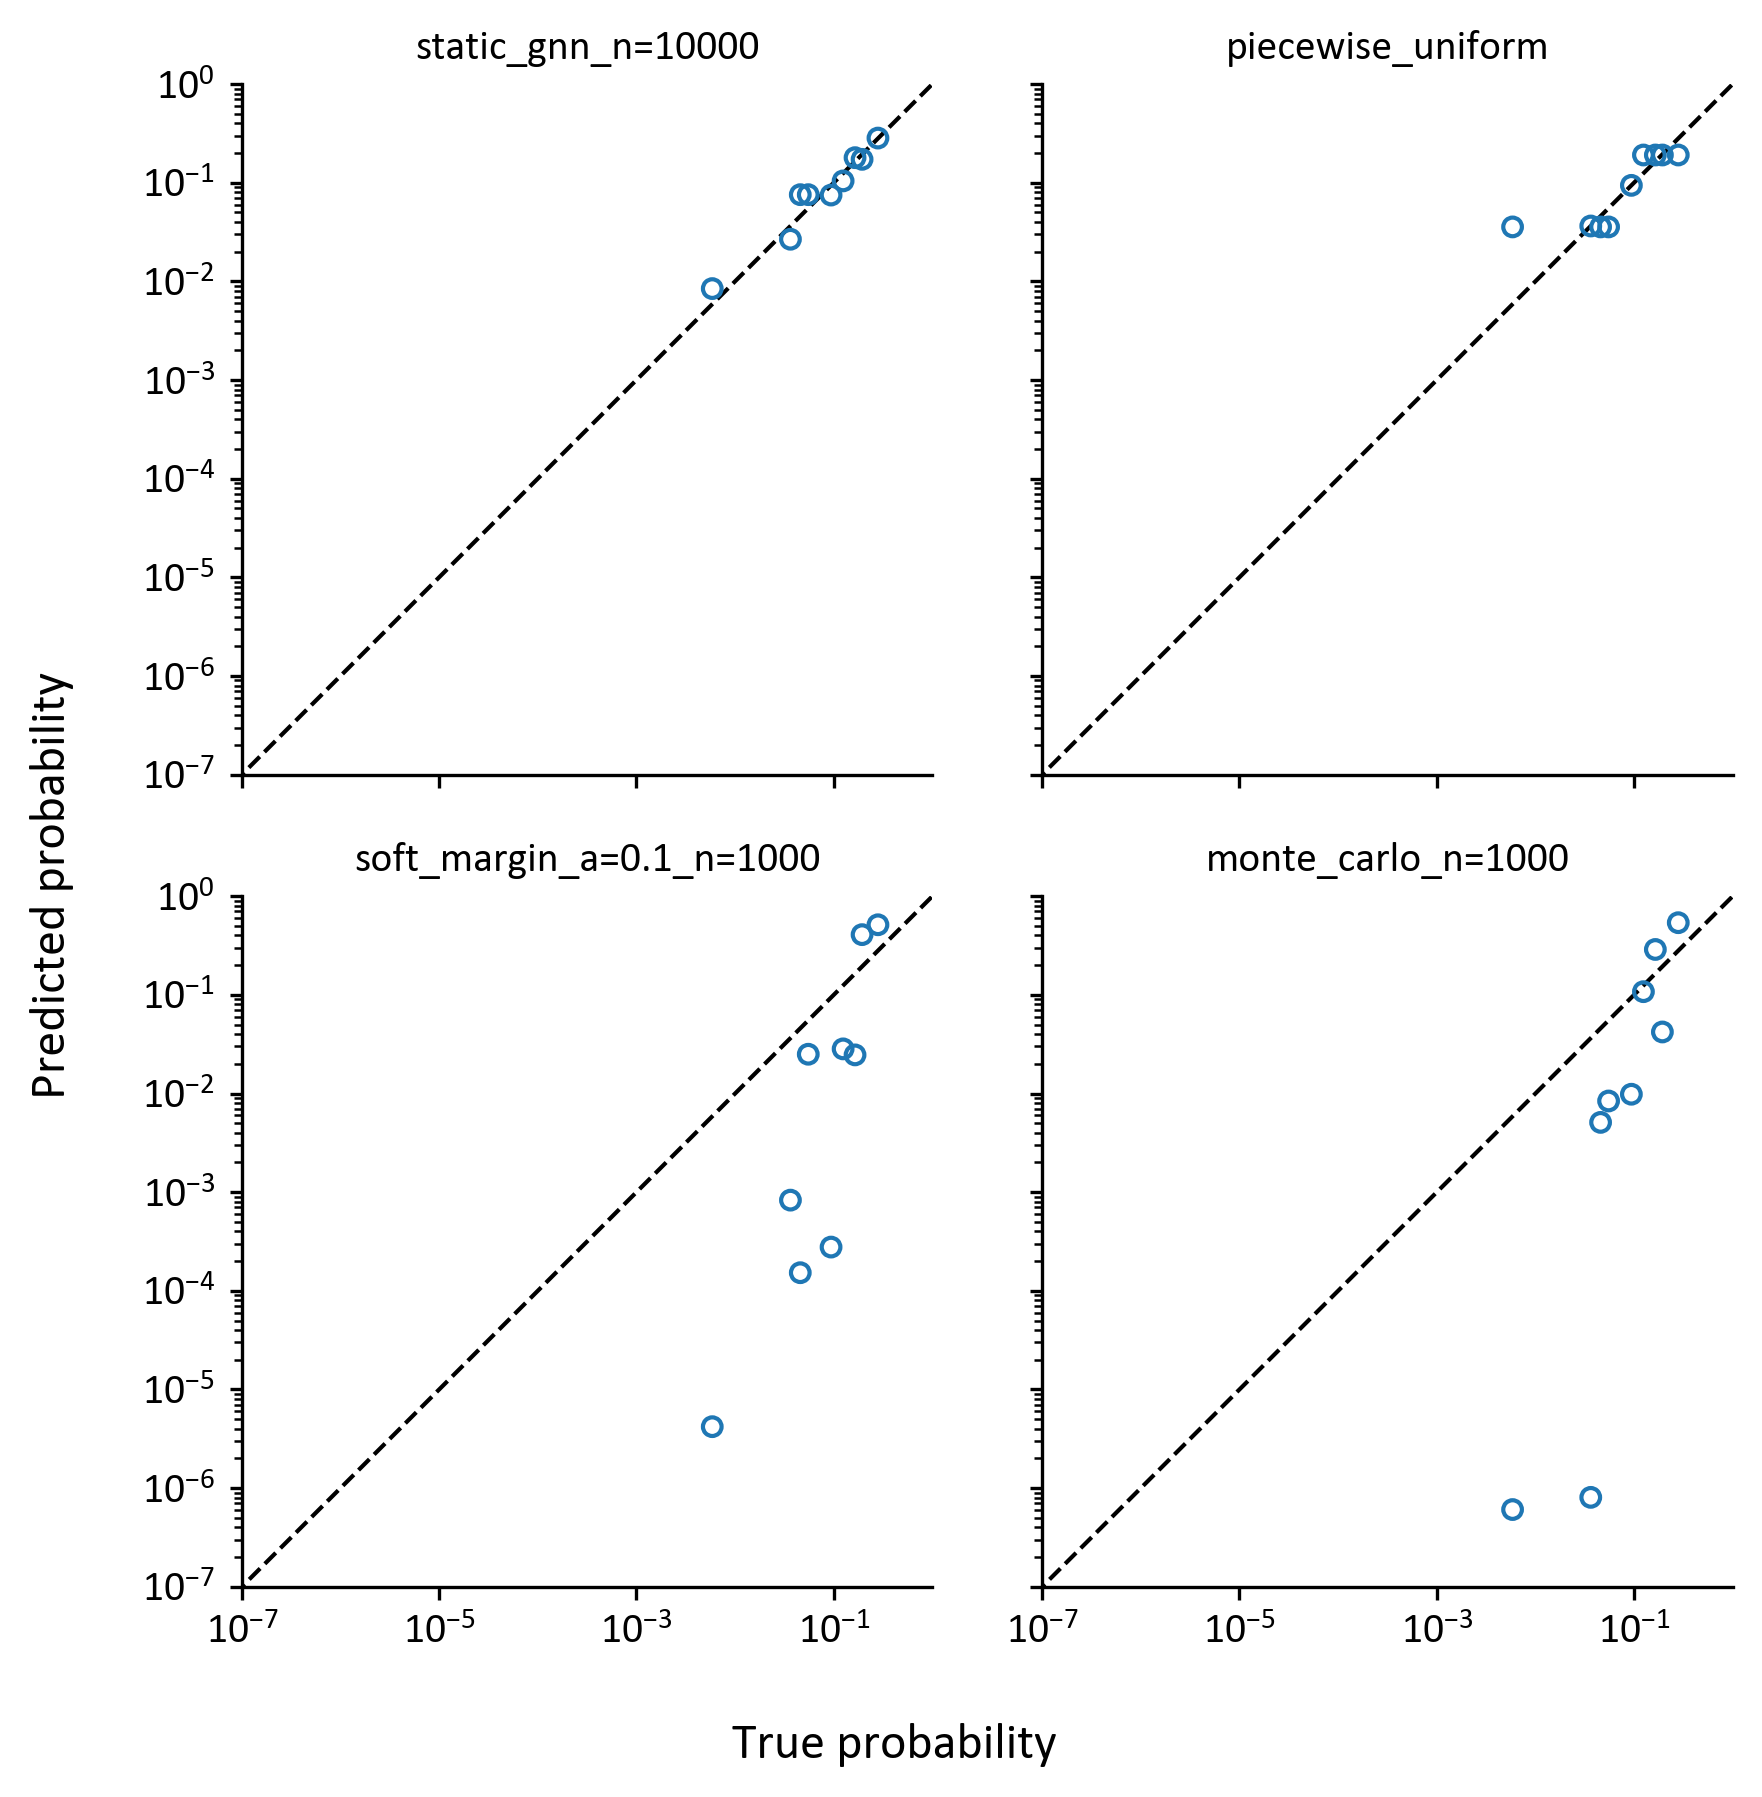

In [43]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, axs = plt.subplots(2, 2, figsize=(6, 6), dpi=300, sharex=True, sharey=True)

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    color = plt.rcParams['axes.prop_cycle'].by_key()['color'][0]
    ax.scatter(df["true_prob"], df[model_pred], s=20, alpha=1, facecolors="none", edgecolors=color)

    # Perfect calibration line
    ax.plot([0, 1], [0, 1], color="black", lw=1.0, linestyle="--", zorder=0)

    ax.set_title(model_pred, fontsize=10)
    ax.set_xlim(1e-7, 1)
    ax.set_ylim(1e-7, 1)
    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(direction="out", length=3, width=0.8)

# Shared axis labels
fig.supxlabel("True probability")
fig.supylabel("Predicted probability")

plt.tight_layout()
#plt.savefig("../images/calibration_run1_4models.pdf", dpi=1200)
#plt.savefig("../images/calibration_run1_4models.svg", dpi=1200)
plt.show()

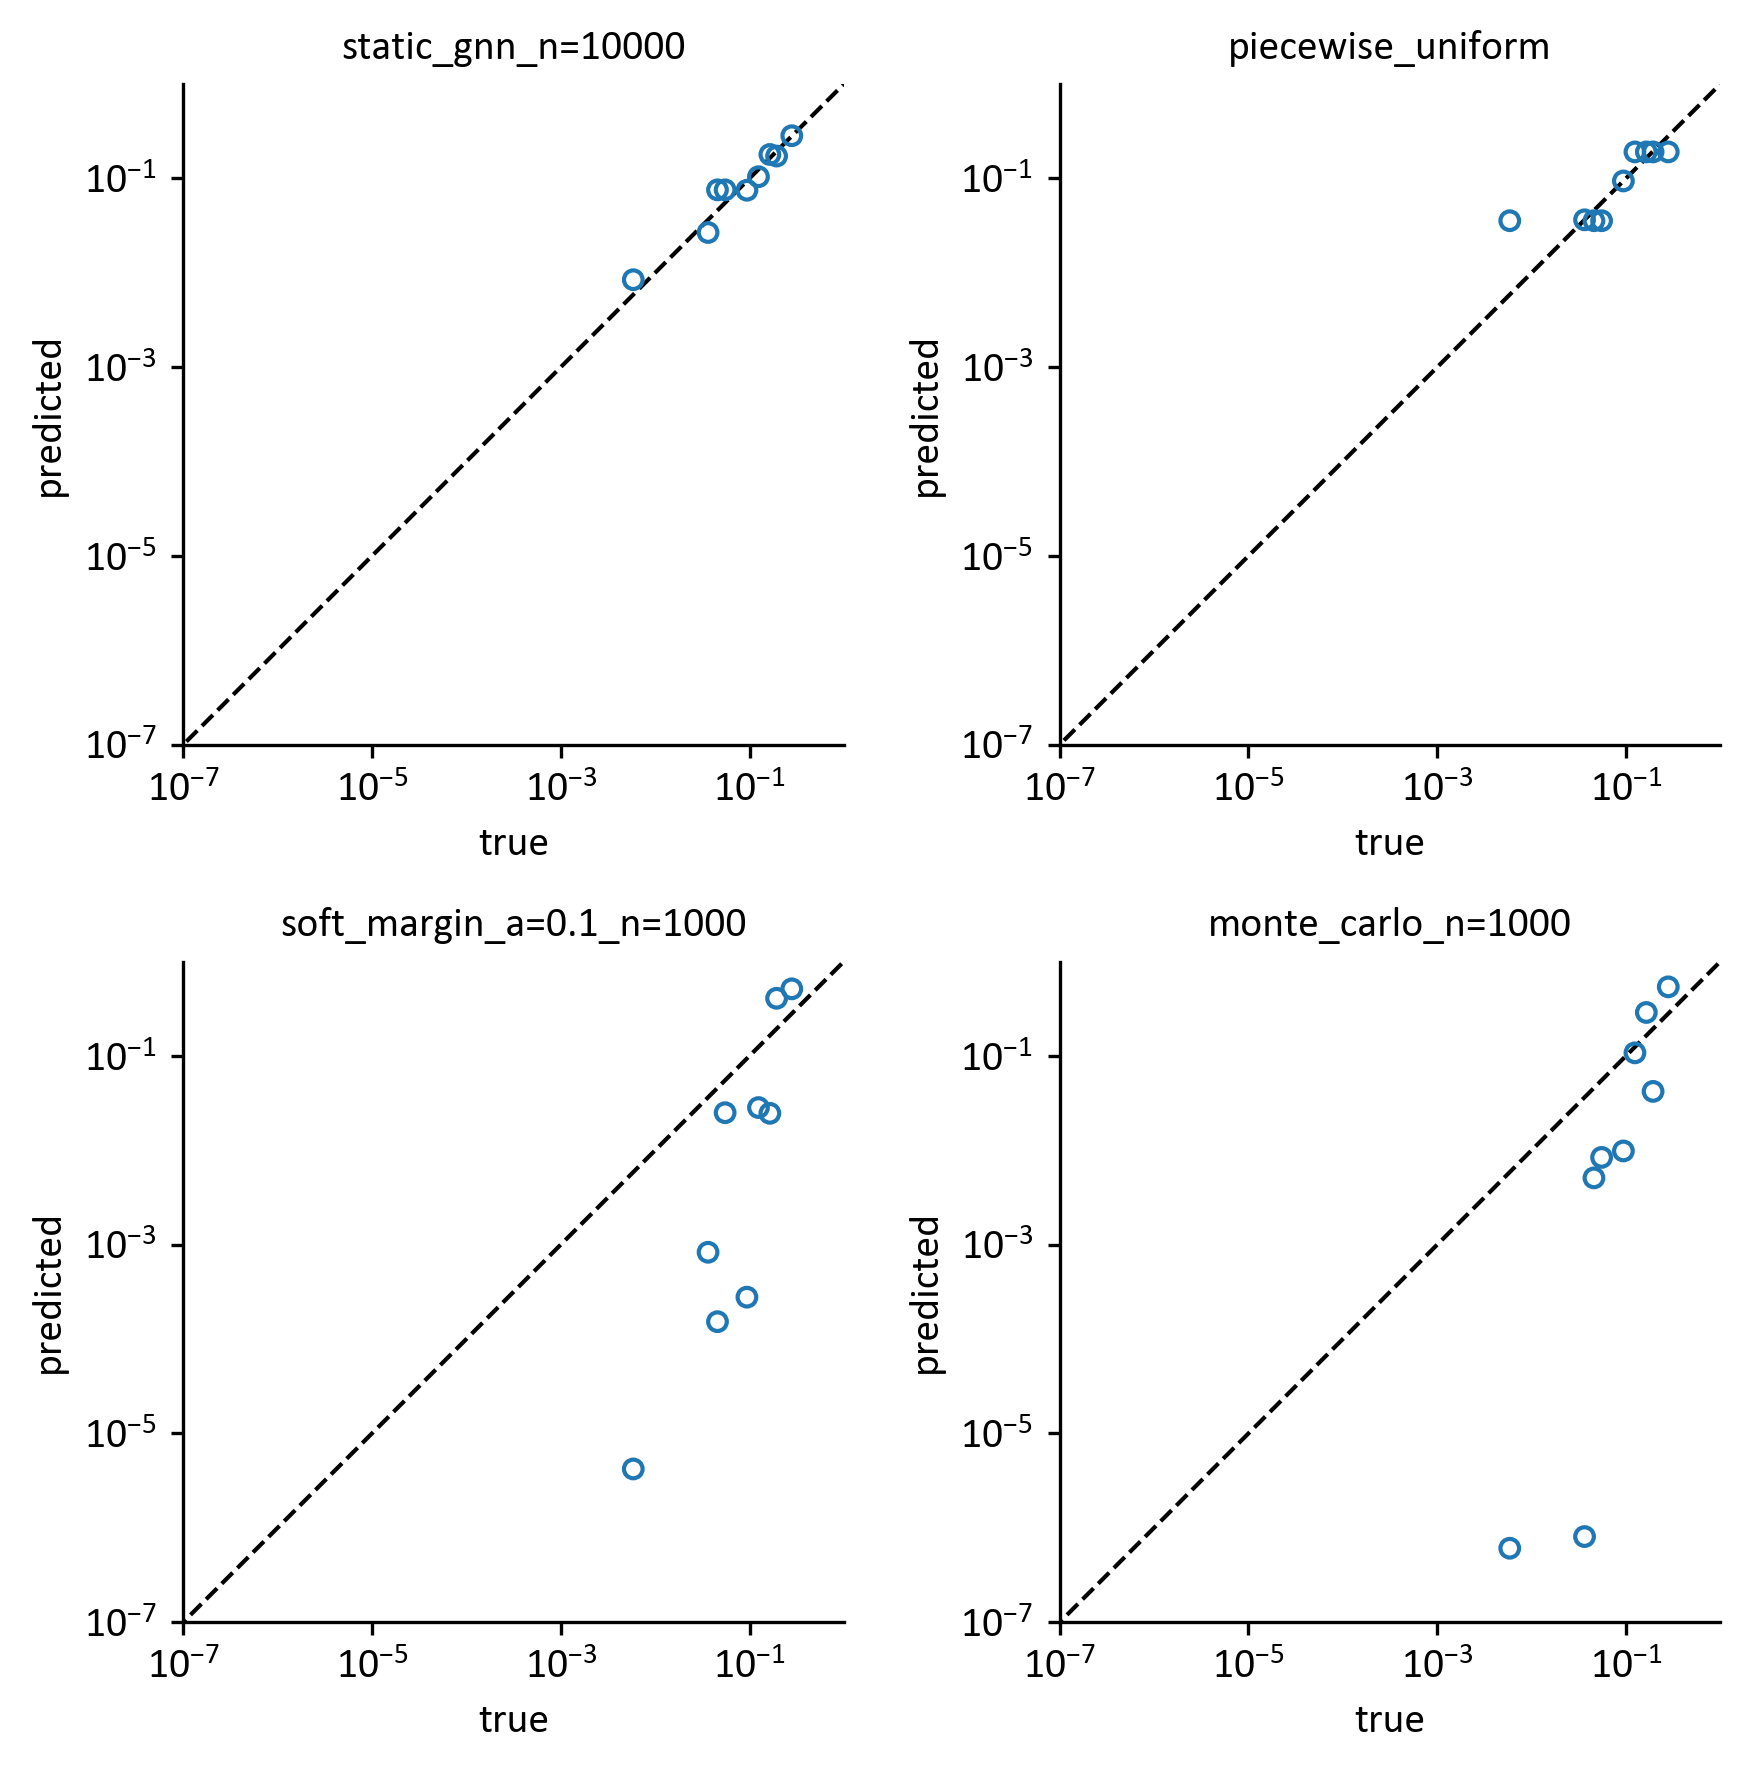

In [44]:
# version to make little calibration plots that i can insert in the graphs with the snapshots in inkscape
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})
fig, axs = plt.subplots(2, 2, figsize=(6, 6), dpi=300, sharex=True, sharey=True)
for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    color = plt.rcParams['axes.prop_cycle'].by_key()['color'][0]
    ax.scatter(df["true_prob"], df[model_pred], s=20, alpha=1, facecolors="none", edgecolors=color)
    # Perfect calibration line
    ax.plot([0, 1], [0, 1], color="black", lw=1.0, linestyle="--", zorder=0)
    ax.set_title(model_pred, fontsize=10)
    ax.set_xlim(1e-7, 1)
    ax.set_ylim(1e-7, 1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(direction="out", length=3, width=0.8)
    # Add labels to each axis
    ax.set_xlabel("true")
    ax.set_ylabel("predicted")
    # Force tick labels to show on all subplots
    ax.tick_params(labelbottom=True, labelleft=True)

plt.tight_layout()
#plt.savefig("../images/calibration_run1_4models_individual.pdf", dpi=1200)
plt.savefig("../images/calibration_run1_4models_individual.svg", dpi=1200)
plt.show()

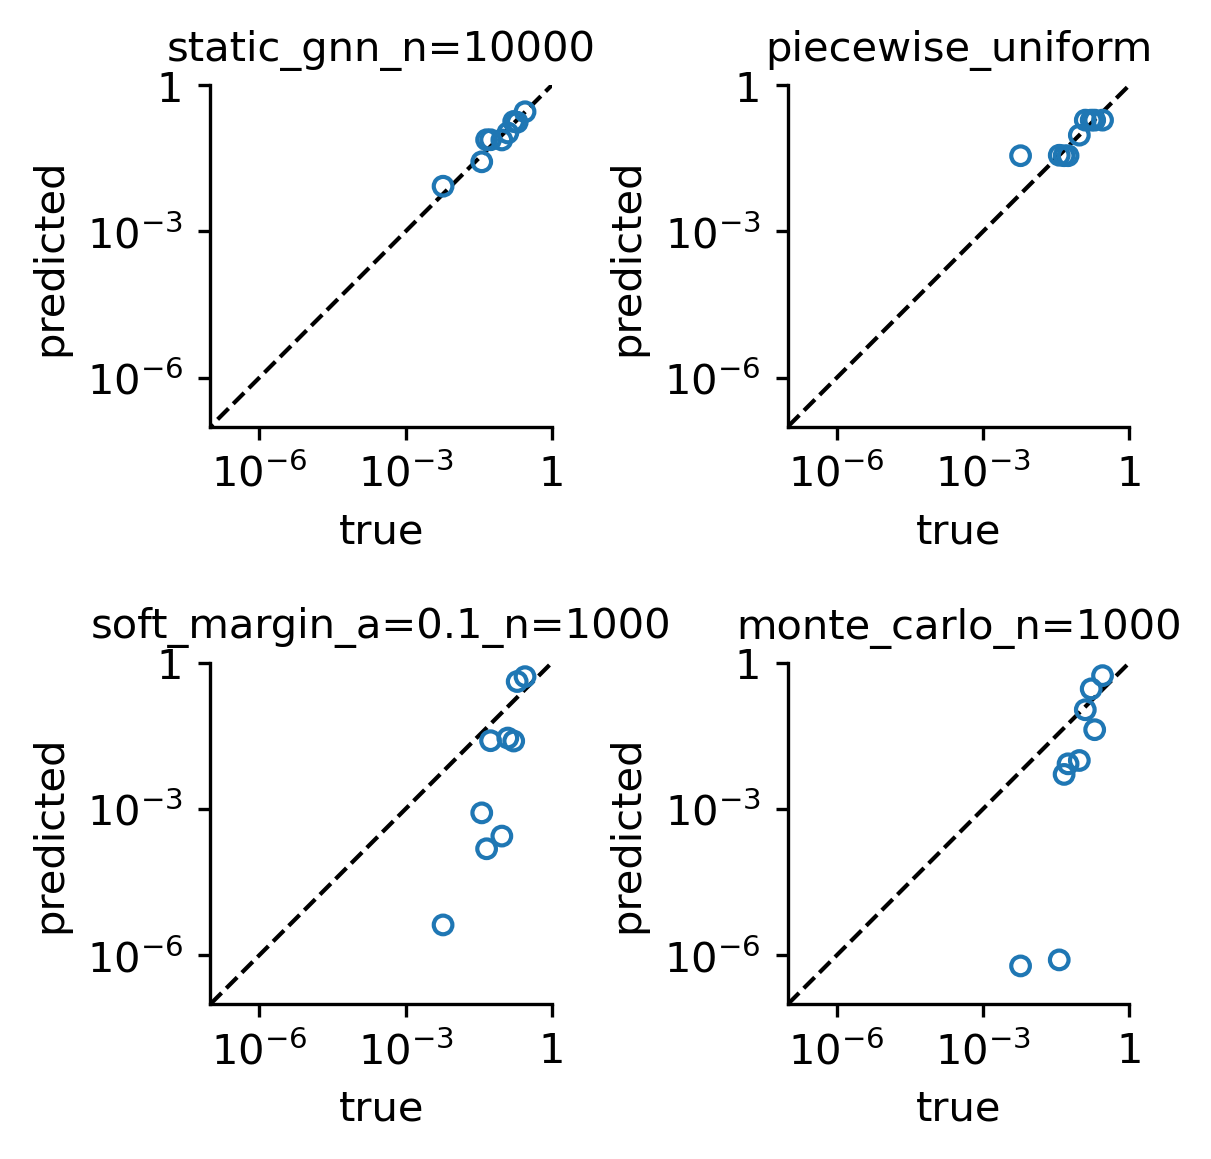

In [59]:
# even smaller calibration plots
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})
fig, axs = plt.subplots(2, 2, figsize=(4, 4), dpi=300, sharex=True, sharey=True)
for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    color = plt.rcParams['axes.prop_cycle'].by_key()['color'][0]
    ax.scatter(df["true_prob"], df[model_pred], s=20, alpha=1, facecolors="none", edgecolors=color)
    # Perfect calibration line
    ax.plot([0, 1], [0, 1], color="black", lw=1.0, linestyle="--", zorder=0)
    ax.set_title(model_pred, fontsize=10)
    ax.set_xlim(1e-7, 1)
    ax.set_ylim(1e-7, 1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_aspect('equal', adjustable='box')
    ax.set_xticks([1e-6, 1e-3, 1])
    ax.set_xticklabels([r"$10^{-6}$", r"$10^{-3}$", "1"])
    ax.set_yticks([1e-6, 1e-3, 1])
    ax.set_yticklabels([r"$10^{-6}$", r"$10^{-3}$", "1"])
    ax.tick_params(direction="out", length=3, width=0.8)
    # Add labels to each axis
    ax.set_xlabel("true")
    ax.set_ylabel("predicted")
    # Force tick labels to show on all subplots
    ax.tick_params(labelbottom=True, labelleft=True)

plt.tight_layout()
#plt.savefig("../images/calibration_run1_4models_individual_small.svg", dpi=1200)
plt.show()

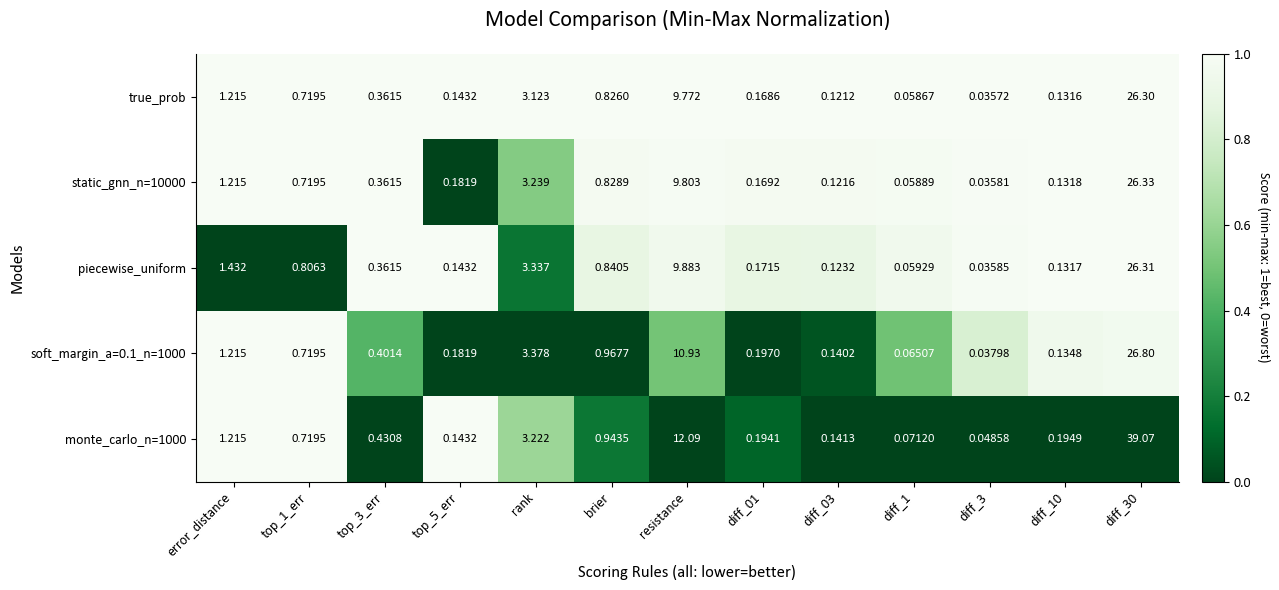

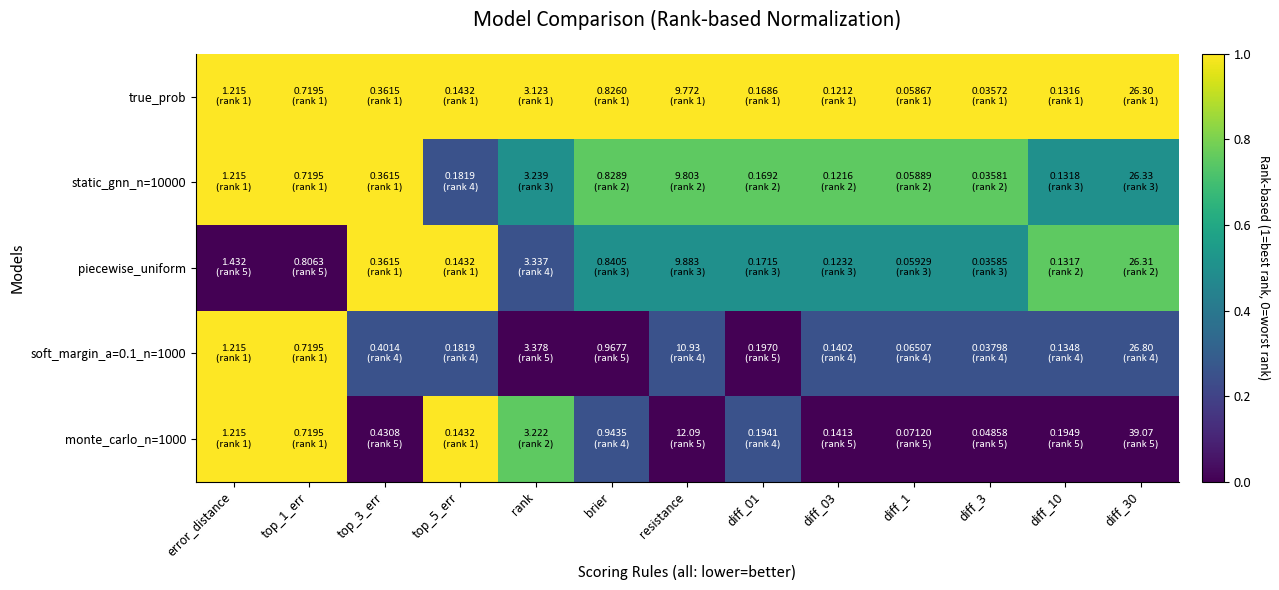

In [46]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[1], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

#plt.savefig("../images/tables_run1_4models.pdf", dpi=300)

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

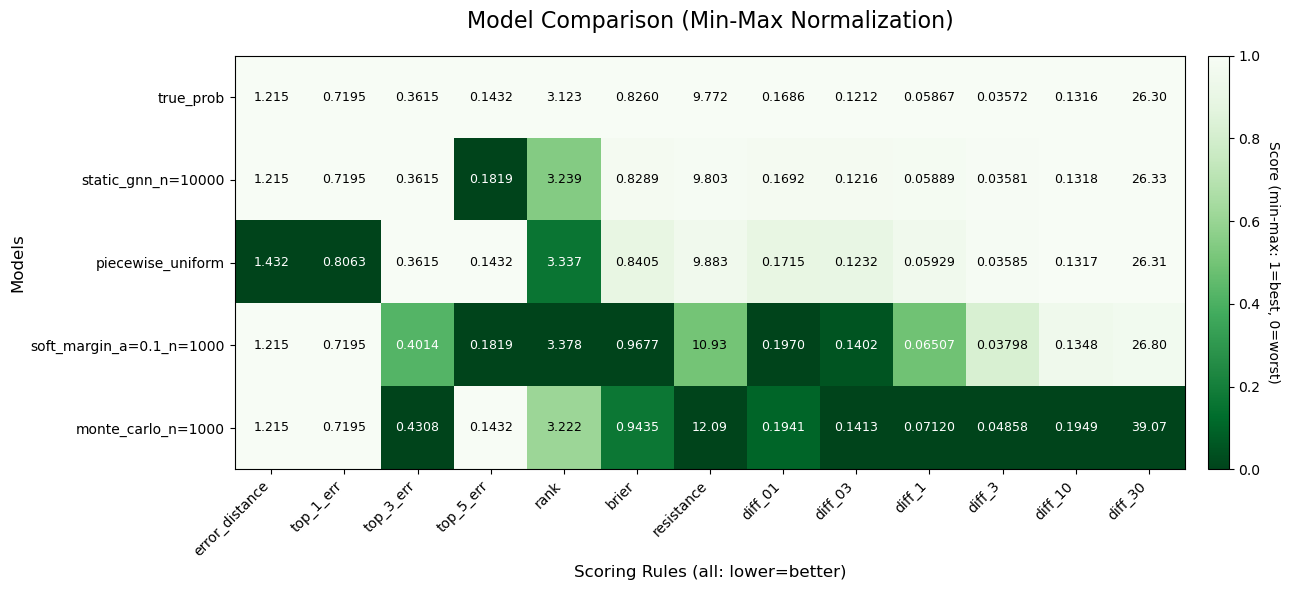

In [47]:
mpl.rcParams.update(mpl.rcParamsDefault)

# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[1], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')

#plt.savefig("../images/score_table_run1_4models.pdf", dpi=300)
#plt.savefig("../images/score_table_run1_4models.svg")
plt.show()


# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

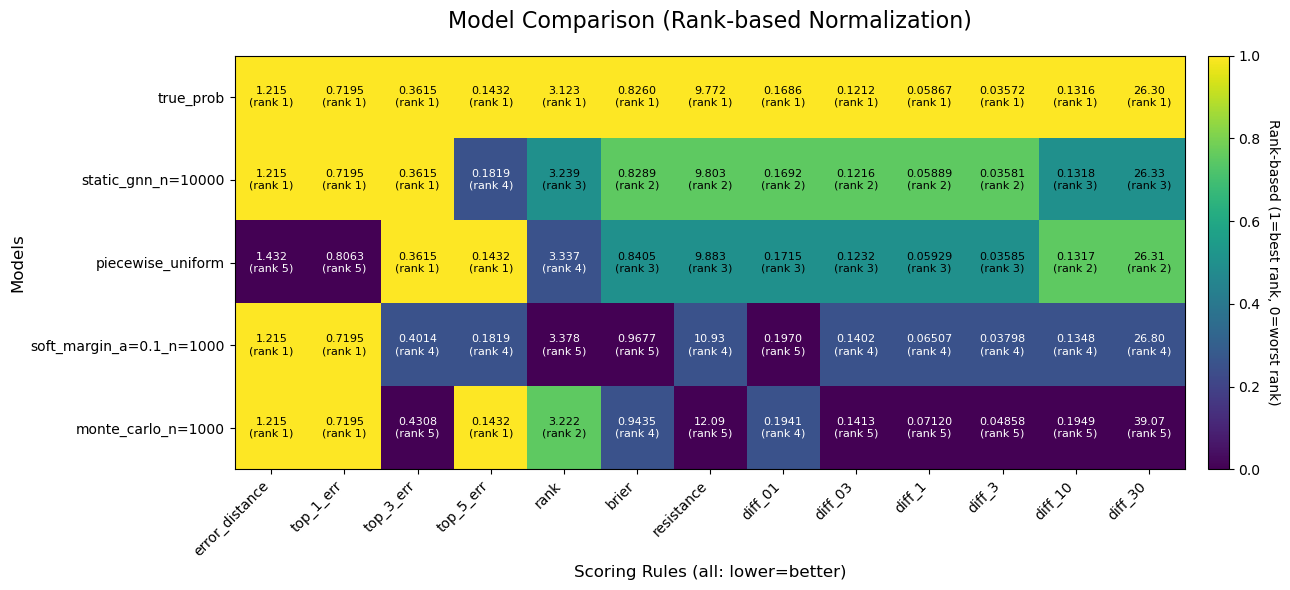

In [48]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[1], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')

#plt.savefig("../images/rank_table_run1_4models.pdf", dpi=300)
#plt.savefig("../images/rank_table_run1_4models.svg")
plt.show()


# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

In [49]:
df_support = dfs[1][dfs[1]["infected"]==1][["node"]+model_columns]
df_support

,node,true_prob,static_gnn_n=10000,piecewise_uniform,soft_margin_a=0.1_n=1000,monte_carlo_n=1000
0,0,0.036385,0.026700,0.036385,0.000830,8.067218e-07
1,1,0.005869,0.008441,0.035603,0.000004,6.068619e-07
4,4,0.124413,0.104186,0.190728,0.028335,1.076719e-01
5,5,0.164319,0.179218,0.190728,0.024625,2.883707e-01
6,6,0.280516,0.283074,0.190728,0.513181,5.385857e-01
11,11,0.093897,0.074876,0.093897,0.000278,9.831190e-03
16,16,0.193662,0.172351,0.190728,0.407594,4.204385e-02
17,17,0.045775,0.075577,0.035603,0.000153,5.096641e-03
21,21,0.055164,0.075577,0.035603,0.025001,8.398611e-03


In [50]:
df_support[df_support["node"].isin([4,5,6,16])].sum()

node                        31.000000
true_prob                    0.762911
static_gnn_n=10000           0.738828
piecewise_uniform            0.762911
soft_margin_a=0.1_n=1000     0.973735
monte_carlo_n=1000           0.976672
dtype: float64

In [51]:
df_support[df_support["node"].isin([11])].sum()

node                        11.000000
true_prob                    0.093897
static_gnn_n=10000           0.074876
piecewise_uniform            0.093897
soft_margin_a=0.1_n=1000     0.000278
monte_carlo_n=1000           0.009831
dtype: float64

In [52]:
df_support[df_support["node"].isin([0,1,17,21])].sum()

node                        39.000000
true_prob                    0.143192
static_gnn_n=10000           0.186296
piecewise_uniform            0.143192
soft_margin_a=0.1_n=1000     0.025988
monte_carlo_n=1000           0.013497
dtype: float64

In [53]:
Escores_df

,error_distance_expected,top_1_err_expected,top_3_err_expected,top_5_err_expected,rank_expected,brier_expected,resistance_expected,diff_01_expected,diff_03_expected,diff_1_expected,diff_3_expected,diff_10_expected,diff_30_expected
model,,,,,,,,,,,,,
true_prob,1.214789,0.719484,0.361502,0.143192,3.123239,0.826013,9.771581,0.168568,0.121208,0.058670,0.035718,0.131613,26.304750
static_gnn_n=10000,1.214789,0.719484,0.361502,0.181925,3.239437,0.828872,9.803427,0.169162,0.121649,0.058894,0.035807,0.131770,26.334093
piecewise_uniform,1.431631,0.806338,0.361502,0.143192,3.336854,0.840549,9.882539,0.171504,0.123176,0.059291,0.035854,0.131702,26.313838
soft_margin_a=0.1_n=1000,1.214789,0.719484,0.401408,0.181925,3.377934,0.967713,10.926394,0.197030,0.140236,0.065067,0.037980,0.134837,26.797853
monte_carlo_n=1000,1.214789,0.719484,0.430751,0.143192,3.221831,0.943537,12.087293,0.194076,0.141317,0.071196,0.048584,0.194922,39.070015


In order to understand why monte_carlo_n=1000 performs so much worse than soft_margin_a=0.1_n=1000 in MCMC one would probably have to perform Laplacian coarse-graining and compute the Brier score on the coarse grained graph at every new scale.

In [54]:
df_support.plot.bar(x="node", y=model_columns)

<Axes: xlabel='node'>

# ImageNet table

In order to have a table in the same style, let me use the scores heatmap function from above also for the ImageNet results

In [60]:
import pandas as pd
import numpy as np

# Data from evaluate.py --graph tree --all
# Columns must have _expected suffix for plot_expected_scores_heatmap()
# Order: improper metrics first, then proper metrics (log-score family, then Brier/RPS family)

data = {
    "top1_err_expected":       [0.179, 0.186, 0.196, 0.212, 0.207, 0.223, 0.247, 0.302, 0.306, 0.323],
    "top5_err_expected":       [0.041, 0.045, 0.054, 0.057, 0.054, 0.065, 0.074, 0.109, 0.117, 0.126],
    "distance@1_expected":     [1.334, 1.390, 1.492, 1.603, 1.570, 1.701, 1.907, 2.413, 2.494, 2.629],
    "distance@5_expected":     [6.465, 6.316, 7.161, 5.969, 6.187, 6.099, 6.302, 6.227, 6.753, 6.457],
    "log-loss_expected":       [0.782, 0.809, 0.938, 0.834, 0.904, 0.957, 1.174, 1.247, 1.360, 1.344],
    "HXE_expected":            [0.0481, 0.0492, 0.0496, 0.0439, 0.0548, 0.0558, 0.0718, 0.0661, 0.0715, 0.0692],
    "Brier_expected":          [0.263, 0.274, 0.296, 0.299, 0.301, 0.322, 0.382, 0.411, 0.424, 0.433],
    "Resistance_expected":     [1837, 1920, 1969, 2003, 2138, 2284, 2904, 2935, 3062, 3148],
}

index = [
    "ConvNeXt-Tiny",
    "Swin-Tiny",
    "ResNet-50",
    "ViT-S/16",
    "EfficientNet-B2",
    "EfficientNet-B0",
    "MobileNetV3-L",
    "ResNet-18",
    "ShuffleNet-V2",
    "MobileNetV3-S",
]

Escores_df = pd.DataFrame(data, index=index)


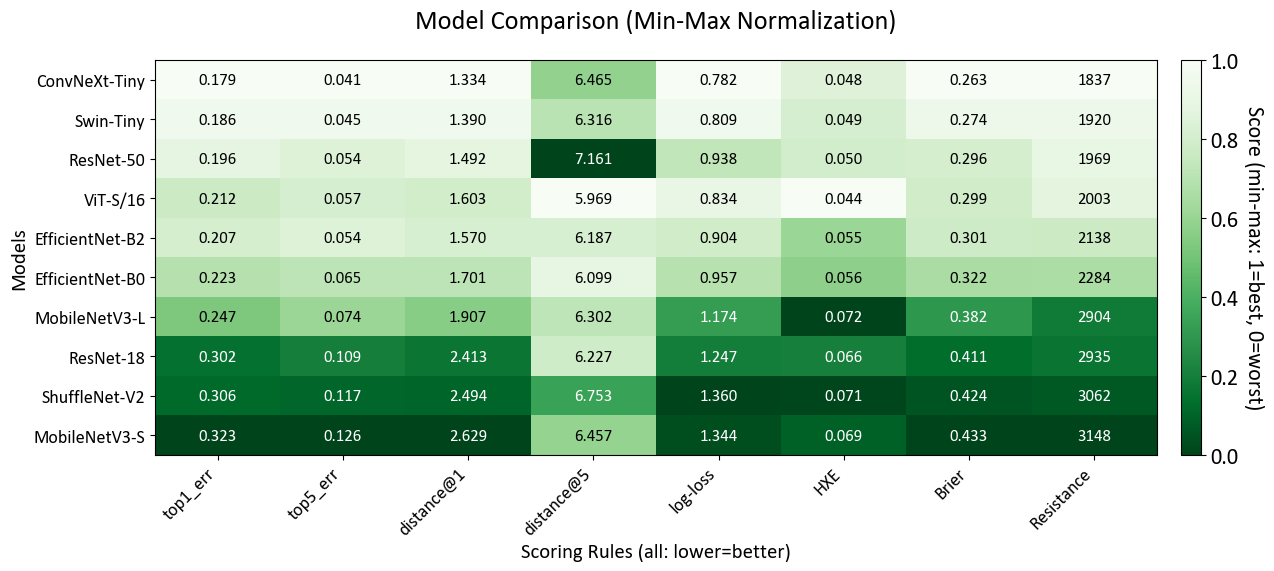

In [85]:
plt.rcParams.update({
    "font.size": 16,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "font.family": "Calibri",
    "svg.fonttype": "none"
})

fig, ax, matrix_norm = plot_expected_scores_heatmap(
    Escores_df,
    normalize_by='minmax',   # or 'rank'
    cmap='Greens_r',           # note: your function uses Greens_r by default (reversed)
    figsize=(14, 6),
    max_decimals=3,
    font_size=12
)
plt.savefig("../images/table_imagenet.svg", dpi=600)

plt.show()